# Notebook 04b: Is the clock right? Timing errors and chronos

**Goal (about 2.5 hours: sections 1 to 8 about 1.5 hours, exercises 1 to 4 about an hour; the stretch exercises 5 to 7 take up to another hour; after notebook 04):** find out how a seismic station knows what time it is, what a wrong clock would do to this project, and whether STAR's clock was right during the swarm. You will measure the evidence for a STAR clock error that is already in the catalog, with an error bar; learn the two pieces of seismology needed to judge it (how earthquakes are located from arrival times, and what ambient seismic noise is); and run the method the Denolle Lab uses to measure and fix clock errors, **chronos**, on a synthetic pair of stations where the answer is known. You leave with a diagnostic you can run on any station, a number for how much timing matters to the splitting results, and a ready-to-run recipe for the real STAR data.

By the end you should be able to say, for STAR:

- how large the apparent clock change is, with its uncertainty, and why the earlier "100 ms peak to peak" overstated it;
- which parts of a splitting result a clock error can reach, and which it cannot;
- how a noise correlation tells a clock error from a change in the rock, and what that needs.

Background reading (20 minutes):

- The README and the *HYS14 — Correction Method* document of [chronos](https://github.com/MaleenKidiwela/chronos) (Maleen Kidiwela, UW). HYS14 is the ocean-bottom seismometer whose clock chronos was written to correct. Read sections 1, 3, 4, 5 and 12 of the method doc; skim the rest. Its companion package **chronfix** applies the correction to miniSEED.
- Shelly, Moran & Thelen (2013), *GRL* 40, 1506-1512, section 2.1, the paragraph that begins "Since variability in digitizers' sampling intervals...". It explains why the 2009 Rainier relocation used only stations "digitized on a common timescale", which is this lesson in one sentence.

Words in **bold** are defined where they first appear; section 9 collects them in a glossary.

In [1]:
# --- setup: make the repo importable and keep figures inline ---
import sys
from pathlib import Path
REPO = Path.cwd().parent if (Path.cwd() / "../rainier_sws").exists() else Path.cwd()
sys.path.insert(0, str(REPO))
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
from rainier_sws import paths, data, measure, quality, stats, timing
print("repo:", REPO)
print("chronos / chronfix importable:", timing.CHRONOS_AVAILABLE,
      "" if timing.CHRONOS_AVAILABLE else "(using the local copies of the chronos numerics in rainier_sws/timing.py)")

repo: /Users/mhemmett/Seismology/rainier-sws-tutorials
chronos / chronfix importable: True 


## 1. How a station knows the time, and why splitting cares

A seismometer measures motion; something else has to say *when*. The sensor's voltage is sampled by a **digitizer**, an analog-to-digital converter that also stamps each sample with a time from its own clock. The stamp is only as good as that clock, and the clock only as good as whatever keeps it right: a **GPS** receiver (good to well under a millisecond while it has a fix, called **GPS lock**), **NTP** (the network time protocol, a computer setting its clock over a network: a few milliseconds on a good network, worse over a radio link), or nothing (a free-running quartz oscillator, which drifts by milliseconds per hour or more).

Where the stamp is put on depends on the station:

- **STAR is analog.** Its metadata describe the chain `L22D08-0621=McVCO=MC8=PSNgw` (notebook 03, section 1): an L-22D geophone feeding a **McVCO**, the voltage-controlled oscillator of **analog FM telemetry**, which turns the voltage into an audio tone whose pitch follows the signal. The tone travels by radio, perhaps through relays, to a receiving site, where a **discriminator** turns the pitch back into a voltage and a digitizer samples it (`MC8` and `PSNgw` name receiving equipment; the metadata do not spell them out). So STAR's samples are timed wherever they are digitized, not on the mountain. The metadata do not say where that is today or how that digitizer keeps time. In 2009 it was a common digitizer in Seattle (Shelly et al., 2013).
- **A digital station** digitizes on site, with its own GPS clock, and the stamps travel with the data, so delays in the telemetry do not matter. The Z5 nodes record this way. RCM, the reference station of section 8, is a broadband station (`HH?` channels); its timing chain is not in this repo, so only its residuals (section 3) vouch for its clock.

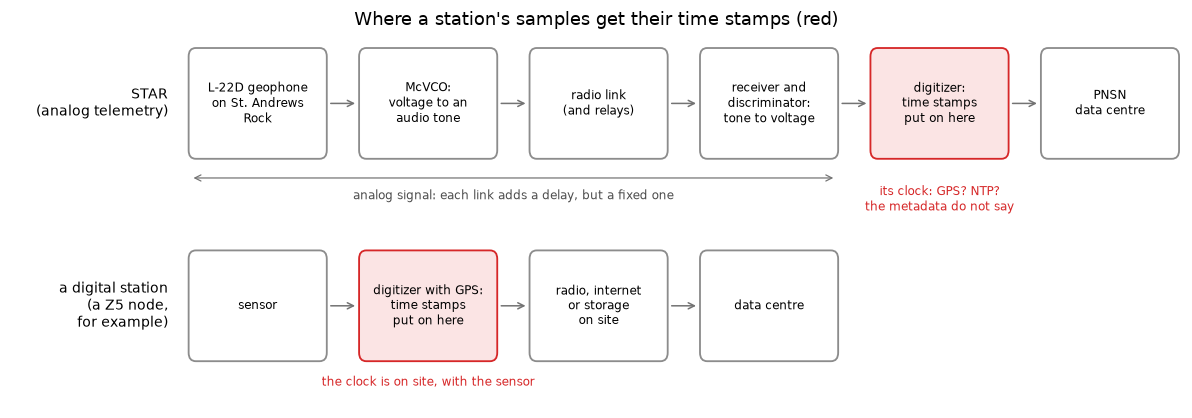

In [2]:
from matplotlib.patches import FancyBboxPatch
chains = [  # (label, boxes, index of the box where the time stamps are put on)
    ("STAR\n(analog telemetry)",
     ["L-22D geophone\non St. Andrews\nRock", "McVCO:\nvoltage to an\naudio tone", "radio link\n(and relays)",
      "receiver and\ndiscriminator:\ntone to voltage", "digitizer:\ntime stamps\nput on here", "PNSN\ndata centre"], 4),
    ("a digital station\n(a Z5 node,\nfor example)",
     ["sensor", "digitizer with GPS:\ntime stamps\nput on here", "radio, internet\nor storage\non site", "data centre"], 1),
]
W, H, GAP = 1.5, 1.0, 0.4
fig, ax = plt.subplots(figsize=(11, 3.9))
for row, (label, boxes, stamp) in enumerate(chains):
    y = 1.9 * (1 - row)
    ax.text(-0.25, y + H / 2, label, ha="right", va="center", fontsize=9)
    for i, text in enumerate(boxes):
        x = i * (W + GAP)
        red = i == stamp
        ax.add_patch(FancyBboxPatch((x, y), W, H, boxstyle="round,pad=0.02,rounding_size=0.08",
                                    fc="#fbe4e4" if red else "white", ec="tab:red" if red else "0.55", lw=1.2))
        ax.text(x + W / 2, y + H / 2, text, ha="center", va="center", fontsize=8)
        if i:
            ax.annotate("", xy=(x - 0.03, y + H / 2), xytext=(x - GAP + 0.03, y + H / 2),
                        arrowprops=dict(arrowstyle="->", color="0.45", lw=1))
x_end = 3 * (W + GAP) + W
ax.annotate("", xy=(0, 1.7), xytext=(x_end, 1.7), arrowprops=dict(arrowstyle="<->", color="0.45", lw=0.8))
ax.text(x_end / 2, 1.5, "analog signal: each link adds a delay, but a fixed one", ha="center", fontsize=8, color="0.3")
ax.text(4 * (W + GAP) + W / 2, 1.5, "its clock: GPS? NTP?\nthe metadata do not say", ha="center", va="center",
        fontsize=8, color="tab:red")
ax.text(1 * (W + GAP) + W / 2, -0.25, "the clock is on site, with the sensor", ha="center", fontsize=8, color="tab:red")
ax.set(xlim=(-2.0, 6 * (W + GAP) - GAP + 0.05), ylim=(-0.45, 3.05))
ax.axis("off")
ax.set_title("Where a station's samples get their time stamps (red)")
plt.tight_layout()

Every link of the analog chain delays the signal, but by a fixed amount: the radio path by microseconds, the filters by tens of milliseconds (section 2 measures STAR's). A fixed delay is harmless, because the station term of section 2 absorbs it. What hurts is a delay that *changes*. A clock can have an **offset** (a constant error), a **drift** (the oscillator runs slightly fast or slow, so the error grows smoothly), and **jumps** (the clock resynchronizes, to GPS for example, and the error snaps back; chronos calls these *triggers*). A station with GPS lock is good to about a millisecond. One that loses lock (snow on the antenna is a real failure mode on a volcano), an ocean-bottom seismometer (no GPS underwater; HYS14 drifted by up to 60 s), or a node with a poor GPS fix, drifts.

Why should a splitting project care? All three channels of a station pass through one digitizer with one clock, so a wrong clock shifts Z, N and E together: **the splitting measurement itself (phi, dt) is immune to an absolute timing error.** Timing reaches the results in four other ways, in the order they will bite this project (section 4 puts numbers on them):

1. **Picks against waveforms.** The S windows are placed from the analyst's pick (notebook 07, section 6: a 30 ms shift of the pick decides whether one event passes the quality cut). PNSN picked on the same data stream we downloaded, so pick and waveform share any clock error today. Correct the waveforms but not the picks, or take picks from one system and waveforms from another (nodes, a re-timed archive), and they no longer line up.
2. **Locations.** An earthquake's location, and so the back azimuth and the incidence angle used to rotate the components into the frame of the incoming ray (the **LQT** frame, notebook 05, section 5), comes from arrival times at many stations (section 2). STAR is the closest station to the swarm, so its picks carry a lot of weight.
3. **The phase-2 catalog.** Step 1 of the research plan (README) rebuilds the catalog from the permanent stations plus 240 GPS-timed nodes. Its **picker** (software that marks P and S arrivals; EQTransformer, a deep-learning one) and **associator** (software that groups picks from many stations into earthquakes; PyOcto) assume that all stations share one timescale. A station with a wandering clock produces outliers that the associator either drops or absorbs into bad locations.
4. **Cross-station methods.** **Template matching** (scanning continuous data with the waveform of a known earthquake to find smaller ones like it) and **double-difference relocation** (locating earthquakes relative to each other from the differences of their arrival times at common stations) compare times between events and stations to a few milliseconds. Shelly et al. (2013) dropped OBSR, PANH and LON from the 2009 relocation for exactly this reason: they were digitized on site, the rest of the network by a common digitizer in Seattle, so only the rest shared one timescale. STAR, analog then too, was in the common group.

## 2. Travel times: what a location does with a pick

An earthquake is described by its **hypocentre** (the latitude, longitude and depth where it started; the **epicentre** is the point on the surface above it) and its **origin time**. A **pick** is the time an analyst, or a picker, marks as the arrival of a wave at a station, and the **travel time** is the pick minus the origin time. The simplest model of a travel time is a straight ray at one speed,

$$t = R / V + c,$$

where $R$ is the **hypocentral distance** (the straight line from hypocentre to station, the station's elevation included; the **epicentral distance** is its horizontal part) and $V$ is the P or the S speed. The slope, $1/V$, is the **slowness** (seconds per km). The constant $c$ is a **station term**: one number per station and phase for everything the model misses near that station, every time: slow rock under the site, the curvature of real rays, the instrument's delay, and any constant clock offset.

`timing.travel_time_residuals` fits that model to the **strict catalog** (`data/catalog/rainier_catalog_strict.csv`, notebook 02: PNSN's reviewed swarm picks, one row per earthquake and station with both a P and an S pick), with one slowness for P, one for S and a station term per station and phase. What is left over for every pick is its **residual**: observed minus predicted travel time.

14285 picks at 40 stations; fitted Vp = 6.11 km/s, Vs = 3.67 km/s, Vp/Vs = 1.66; slowness 0.164 s/km (P) and 0.272 s/km (S)
station terms (s): {'STAR': {'P': 0.008, 'S': 0.158}, 'RCM': {'P': -0.026, 'S': 0.121}, 'MILD': {'P': 0.05, 'S': 0.357}, 'LON': {'P': 0.064, 'S': 0.357}}
STAR's instrument delays a wave packet by 93 ms at 3 Hz, 57 ms at 5 Hz, 44 ms at 10 Hz, 47 ms at 15 Hz


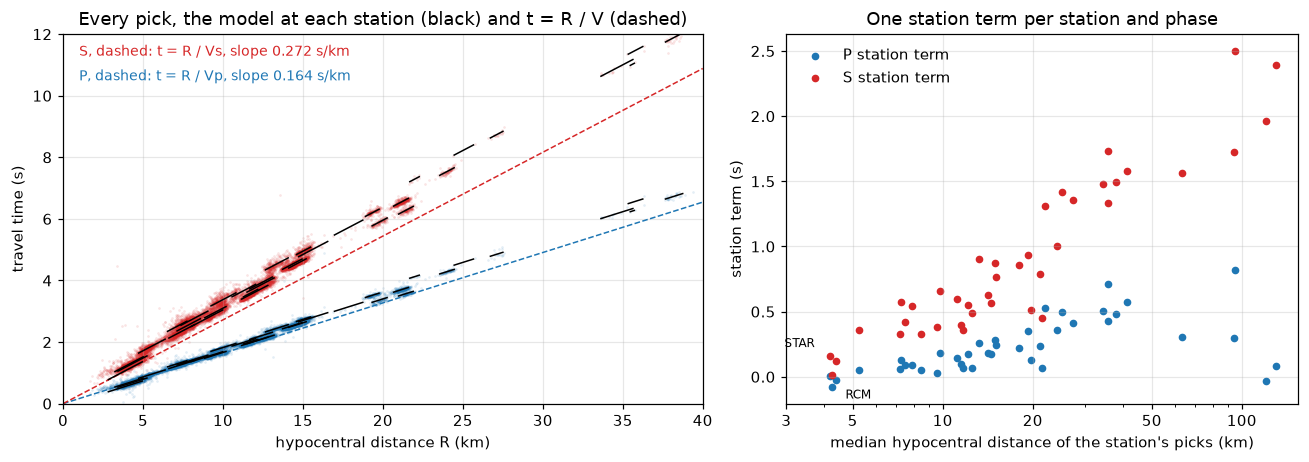

In [3]:
cat = pd.read_csv(paths.STRICT_CATALOG_CSV)
sta = data.load_stations().set_index("station")
res, fit = timing.travel_time_residuals(cat, sta)
vp, vs = fit["vp_km_s"], fit["vs_km_s"]
print(f"{len(res)} picks at {res.station.nunique()} stations; fitted Vp = {vp:.2f} km/s, Vs = {vs:.2f} km/s, "
      f"Vp/Vs = {vp / vs:.2f}; slowness {1 / vp:.3f} s/km (P) and {1 / vs:.3f} s/km (S)")
terms = pd.DataFrame({"P": fit["const_p"], "S": fit["const_s"], "R_km": res.groupby("station").R_km.median()})
print("station terms (s):", terms.loc[["STAR", "RCM", "MILD", "LON"], ["P", "S"]].round(3).to_dict("index"))

# STAR's instrument: the group delay (minus the slope of the phase against angular frequency) of its response
resp = data.load_inventory("STAR").select(channel="EHE")[0][0][0].response
f_gd = np.linspace(1, 30, 2901)
phase = np.unwrap(np.angle(resp.get_evalresp_response_for_frequencies(f_gd, output="VEL")))
group_delay = pd.Series(-np.gradient(phase, 2 * np.pi * f_gd), index=f_gd)
print("STAR's instrument delays a wave packet by",
      ", ".join(f"{1000 * group_delay.iloc[np.argmin(np.abs(f_gd - x))]:.0f} ms at {x} Hz" for x in (3, 5, 10, 15)))

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1.25, 1]})
R = np.array([0, 40.0])
for ph, col, v, c in (("P", "tp", vp, "tab:blue"), ("S", "ts", vs, "tab:red")):
    ax0.scatter(res.R_km, res[col], s=3, color=c, alpha=0.12, lw=0)
    ax0.plot(R, R / v, color=c, lw=1, ls="--")
    for s_, g_ in res.groupby("station"):          # the model at each station: slope 1/V, offset by its station term
        r_ = np.array([g_.R_km.quantile(0.05), g_.R_km.quantile(0.95)])
        ax0.plot(r_, r_ / v + terms.loc[s_, ph], color="k", lw=1)
    ax0.text(1, 11.3 if ph == "S" else 10.5, f"{ph}, dashed: t = R / V{ph.lower()}, slope {1 / v:.3f} s/km", color=c, fontsize=9)
    ax1.scatter(terms.R_km, terms[ph], s=16, color=c, label=f"{ph} station term")
ax1.annotate("STAR", (terms.R_km["STAR"], terms.S["STAR"]), xytext=(-30, 6), textcoords="offset points", fontsize=8)
ax1.annotate("RCM", (terms.R_km["RCM"], terms.P["RCM"]), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax0.set(xlim=(0, 40), ylim=(0, 12), xlabel="hypocentral distance R (km)", ylabel="travel time (s)",
        title="Every pick, the model at each station (black) and t = R / V (dashed)")
ax1.set(xscale="log", xlabel="median hypocentral distance of the station's picks (km)", ylabel="station term (s)",
        title="One station term per station and phase")
ax1.legend(frameon=False, loc="upper left")
import matplotlib.ticker as mticker
ax1.set_xticks([3, 5, 10, 20, 50, 100]); ax1.xaxis.set_major_formatter(mticker.FormatStrFormatter("%g"))
ax1.xaxis.set_minor_formatter(mticker.NullFormatter())
plt.tight_layout()

- The fitted speeds are Vp = 6.11 km/s and Vs = 3.67 km/s, so **Vp/Vs** = 1.66: S is that much slower than P, and its slowness that much larger. Section 3 uses this ratio to tell a clock from the earth.
- The station terms (right) grow with distance, from about zero at STAR and RCM to several tenths of a second for P and 1 to 2.5 s for S at the most distant stations. That is not slow rock under those stations: one straight-line speed cannot fit near and far stations at once (real rays curve down into faster rock), and the terms absorb the misfit. In the left panel you can see it as the black pieces of line, each the model at one station, stepping up away from the dashed line through zero. So the terms are not clock offsets, and should be compared with care. For a clock, what matters is how the residual *changes with time* at one station.
- One fixed delay can be computed exactly: STAR's own instrument. The **group delay** of a filter, minus the slope of its phase response against angular frequency, is how late it makes a wave packet at each frequency. STAR's response (notebook 03, section 1) delays a packet by 93 ms at 3 Hz, 57 ms at 5 Hz and 44 ms at 10 Hz, so every pick at STAR is late by roughly that much, every time, and the station term absorbs it. A delay this size is harmless as long as it does not change.

### How a location is solved, and why origin time trades off against depth

To **locate** an earthquake, a program searches for the hypocentre and origin time whose predicted arrival times best match the picks at all stations, usually in the least-squares sense. (PNSN uses a layered velocity model rather than one speed, but the idea is the same.) For any trial hypocentre the best origin time is easy: whatever makes the residuals average zero. Depth is the hard part. For an earthquake under the network, a deeper source makes every travel time longer by a similar amount, and an earlier origin time compensates for most of that. Depth and origin time **trade off**: many pairs of them fit the picks almost equally well.

The cell shows it for the figure-3 event of notebooks 03 and 05, with our straight-ray model: hold the epicentre where PNSN put it, move the source up and down, solve for the origin time at each depth, and look at the misfit. Then make STAR's picks 50 ms late, as a late STAR clock would, and do it again.

event 61504668: P and S picks at 7 stations (COPP, LON, PANH, PARA, RCM, SIFT, STAR); PNSN depth 0.39 km below sea level
       picks as they are: best depth 0.49 km, RMS 65 ms there and 93 / 94 ms 1 km shallower / deeper; origin-time correction +15 ms, changing -93 ms per km deeper
 STAR's picks 50 ms late: best depth 0.63 km, RMS 73 ms there and 100 / 100 ms 1 km shallower / deeper; origin-time correction +11 ms, changing -95 ms per km deeper
STAR 50 ms late moves the best depth by +140 m


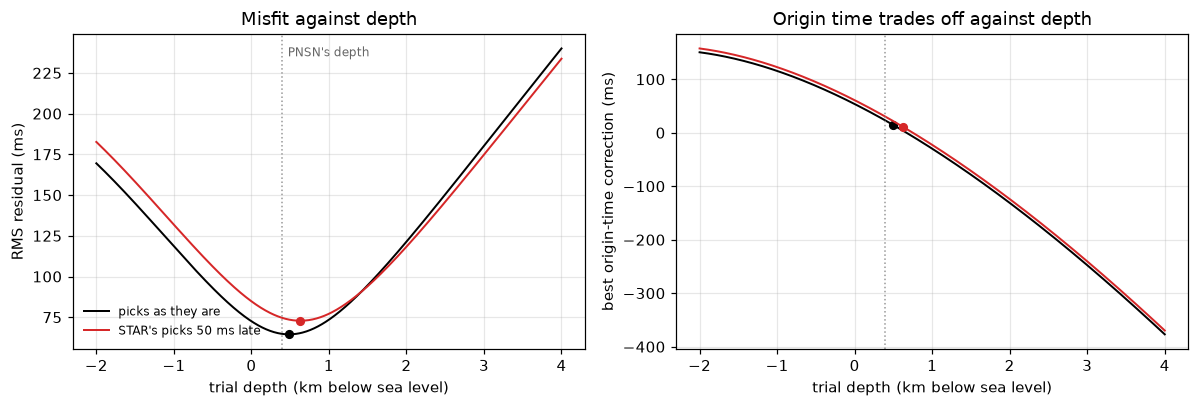

In [4]:
# Local coordinates in km: x east and y north of STAR, z down from sea level (event_depth is km below sea level)
lat0, lon0 = sta.loc["STAR", "lat"], sta.loc["STAR", "lon"]
KM_PER_DEG = (111.32 * np.cos(np.radians(lat0)), 110.57)        # km per degree of longitude and of latitude here
sta_xyz = pd.DataFrame({"x": (sta.lon - lon0) * KM_PER_DEG[0], "y": (sta.lat - lat0) * KM_PER_DEG[1],
                        "z": -sta.elevation / 1000})

def trial_residuals(g, trials, star_shift=0.0):
    """Residuals (s) of one event's P and S picks (its rows of `res`) for each trial hypocentre (rows of `trials`:
    x, y, z in km) with the origin time solved for, and that origin-time correction (s). Straight rays, the fitted
    Vp and Vs and the station terms. `star_shift` makes STAR's picks that much later, as a late clock would."""
    stn = np.r_[g.station.values, g.station.values]
    obs = np.r_[g.tp.values, g.ts.values] + star_shift * (stn == "STAR")
    slow = np.r_[np.full(len(g), 1 / vp), np.full(len(g), 1 / vs)]
    term = np.r_[fit["const_p"].loc[g.station].values, fit["const_s"].loc[g.station].values]
    s = sta_xyz.loc[stn]
    R = np.sqrt(sum((trials[:, [i]] - s[c].to_numpy()) ** 2 for i, c in enumerate("xyz")))
    r = obs - (R * slow + term)
    t0 = r.mean(axis=1)                       # the best origin-time correction makes the residuals average zero
    return r - t0[:, None], t0

STAR_LATE = 0.05                              # s: a STAR clock this late, to see what a location does with it
ev = res[res.evid == 61504668]                # the figure-3 event of notebooks 03 and 05
x0, y0 = (ev.event_lon.iloc[0] - lon0) * KM_PER_DEG[0], (ev.event_lat.iloc[0] - lat0) * KM_PER_DEG[1]
depths = np.arange(-2.0, 4.0001, 0.01)        # km below sea level (STAR is at -3.4)
trials = np.column_stack([np.full_like(depths, x0), np.full_like(depths, y0), depths])
print(f"event 61504668: P and S picks at {len(ev)} stations ({', '.join(sorted(ev.station))}); "
      f"PNSN depth {ev.event_depth.iloc[0]:.2f} km below sea level")

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
best = {}
for shift, c, label in ((0.0, "k", "picks as they are"), (STAR_LATE, "tab:red", f"STAR's picks {1000 * STAR_LATE:.0f} ms late")):
    r, t0 = trial_residuals(ev, trials, shift)
    rms = np.sqrt((r ** 2).mean(axis=1))
    k = int(np.argmin(rms))
    best[shift] = (depths[k], t0[k])
    ax0.plot(depths, 1000 * rms, color=c, lw=1.3, label=label)
    ax0.plot(depths[k], 1000 * rms[k], "o", color=c, ms=5)
    ax1.plot(depths, 1000 * t0, color=c, lw=1.3)
    ax1.plot(depths[k], 1000 * t0[k], "o", color=c, ms=5)
    up, down = np.argmin(np.abs(depths - depths[k] + 1)), np.argmin(np.abs(depths - depths[k] - 1))
    print(f"{label:>24}: best depth {depths[k]:.2f} km, RMS {1000 * rms[k]:.0f} ms there and {1000 * rms[up]:.0f} / "
          f"{1000 * rms[down]:.0f} ms 1 km shallower / deeper; origin-time correction {1000 * t0[k]:+.0f} ms, "
          f"changing {1000 * (t0[down] - t0[k]):+.0f} ms per km deeper")
for ax in (ax0, ax1):
    ax.axvline(ev.event_depth.iloc[0], color="0.6", ls=":", lw=1)
ax0.text(ev.event_depth.iloc[0] + 0.08, ax0.get_ylim()[1] * 0.97, "PNSN's depth", fontsize=8, color="0.4", va="top")
ax0.set(xlabel="trial depth (km below sea level)", ylabel="RMS residual (ms)", title="Misfit against depth")
ax1.set(xlabel="trial depth (km below sea level)", ylabel="best origin-time correction (ms)",
        title="Origin time trades off against depth")
ax0.legend(frameon=False, loc="lower left", fontsize=8)
plt.tight_layout()
print(f"STAR {1000 * STAR_LATE:.0f} ms late moves the best depth by {1000 * (best[STAR_LATE][0] - best[0.0][0]):+.0f} m")

- The origin time moves by -93 ms for every km the source goes deeper (right): a deeper earthquake must have started earlier to fit the same picks.
- The misfit has a clear minimum (left), 65 ms of RMS at 0.49 km below sea level against 93 and 94 ms a kilometre either side, but with only 7 stations and a crude model the depth is uncertain by hundreds of metres.
- Make STAR's picks 50 ms late and the best depth moves 140 m deeper. STAR is almost directly above the swarm, so a late STAR pick looks like a longer, more vertical path. Exercise 7 relocates 133 events in three dimensions: a median of 190 m deeper, 36 m sideways.

Two consequences for this lesson. First, PNSN *used* STAR's picks to locate these earthquakes, so part of any STAR clock error went into the depths and origin times, and the residuals show only the part that could not be absorbed: the true error could be larger. Second, the three kinds of error leave different fingerprints. A wrong origin time adds the same seconds to P and to S at *every* station. A wrong clock adds the same seconds to P and to S at *one* station. A wrong location or speed adds seconds in proportion to slowness: about Vp/Vs = 1.7 times more to S than to P. Section 3 is built on that.

## 3. Diagnostic 1: the catalog already knows

The test: residuals that wander in time *identically* on P and S at one station are a clock; residuals that wander with S about 1.7 times P are the earth or the location; a shift common to every station is an origin time.

`timing.daily_residuals` takes the median residual of each day with at least 5 picks. With `n_boot` it adds the **bootstrap** standard error of each daily median: resample that day's picks with replacement, recompute the median, repeat, and take the standard deviation of the results (notebook 07 uses the bootstrap throughout). Here is STAR, with what the earthquakes were doing underneath it. The shaded periods are used further down.

22 days with >= 5 picks; standard error of a daily median: 3 to 13 ms (P) up to 16 July, 10 to 32 ms after; picks per day 54 to 261, then 5 to 26
daily medians up to 25 July: epicentral distance 1.9 to 2.8 km, depth -0.2 to 0.7 km below sea level


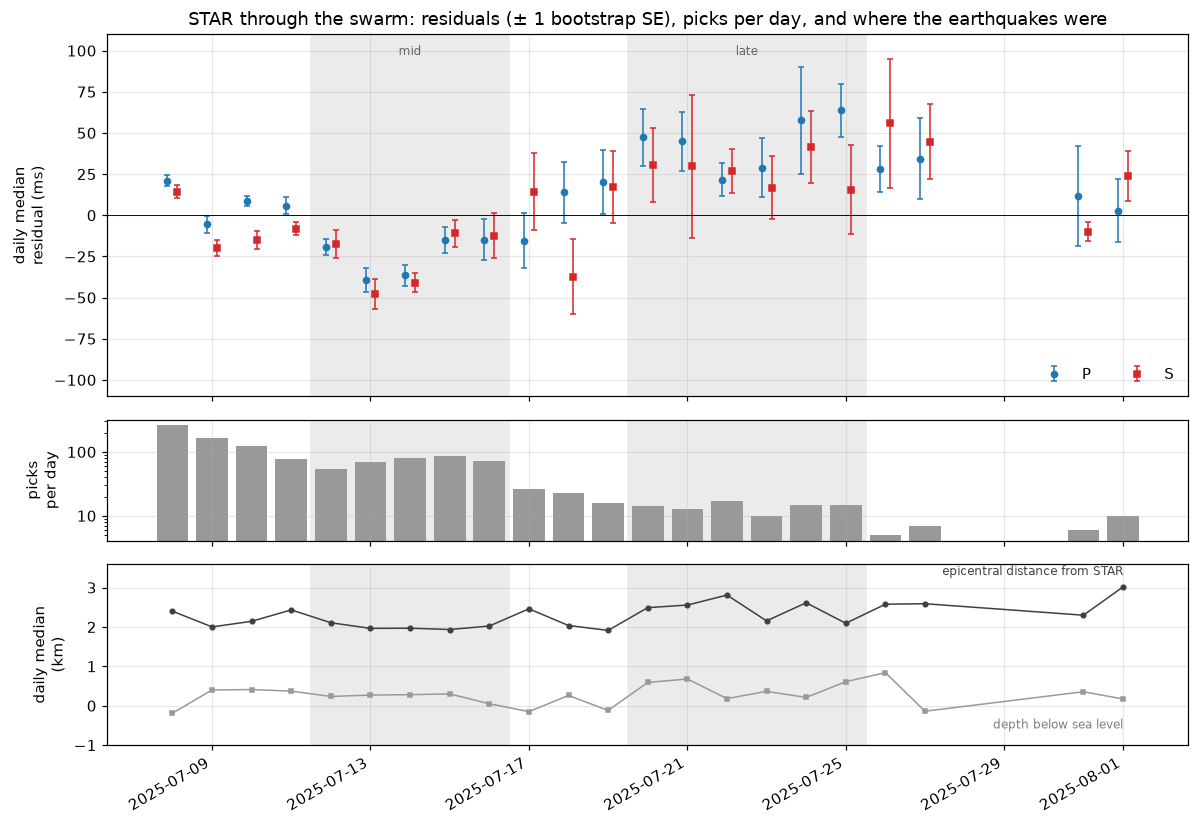

In [5]:
from obspy.geodetics import gps2dist_azimuth
N_BOOT = 500                                   # bootstrap resamples behind each daily standard error
STATIONS = ["STAR", "RCM", "MILD", "LON", "RER"]
daily = {s: timing.daily_residuals(res, s, n_boot=N_BOOT) for s in STATIONS}
# the mid-swarm low and the late high of STAR's curve, used below for a sturdier number (end dates exclusive)
MID = (pd.Timestamp("2025-07-12", tz="UTC"), pd.Timestamp("2025-07-17", tz="UTC"))
LATE = (pd.Timestamp("2025-07-20", tz="UTC"), pd.Timestamp("2025-07-26", tz="UTC"))

star = res[res.station == "STAR"].copy()
s_lat, s_lon, _ = data.station_coords("STAR")
star["epi_km"] = [gps2dist_azimuth(s_lat, s_lon, la, lo)[0] / 1000 for la, lo in zip(star.event_lat, star.event_lon)]
d = daily["STAR"]
where = star.groupby(star.origin_time.dt.floor("D")).agg(epi=("epi_km", "median"), depth=("event_depth", "median")).loc[d.index]

import matplotlib.dates as mdates
def shade_periods(ax, label=False):
    """Shade STAR's mid and late periods (days are plotted at midnight, so each day's band starts 12 h before)."""
    for (a, b), name in ((MID, "mid"), (LATE, "late")):
        ax.axvspan(a - pd.Timedelta(hours=12), b - pd.Timedelta(hours=12), color="0.92", zorder=0)
        if label:
            ax.text(mdates.date2num(a + (b - a) / 2 - pd.Timedelta(hours=12)), 0.97, name, transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=8, color="0.4")

half = pd.Timedelta(hours=3)                   # P and S drawn a little apart so their error bars do not overlap
fig, axes = plt.subplots(3, 1, figsize=(11, 7.6), sharex=True, gridspec_kw={"height_ratios": [3, 1, 1.5]})
axes[0].errorbar(d.index - half, 1000 * d.res_p, yerr=1000 * d.se_p, fmt="o", ms=4, color="tab:blue", lw=1, capsize=2, label="P")
axes[0].errorbar(d.index + half, 1000 * d.res_s, yerr=1000 * d.se_s, fmt="s", ms=4, color="tab:red", lw=1, capsize=2, label="S")
axes[0].axhline(0, color="k", lw=0.6)
axes[0].set(ylabel="daily median\nresidual (ms)", ylim=(-110, 110),
            title="STAR through the swarm: residuals (± 1 bootstrap SE), picks per day, and where the earthquakes were")
axes[0].legend(loc="lower right", ncol=2, frameon=False)
axes[1].bar(d.index, d.n, width=0.8, color="0.6")
axes[1].set(yscale="log", ylabel="picks\nper day", yticks=[10, 100], yticklabels=["10", "100"])
axes[2].plot(where.index, where.epi, "o-", ms=3, color="0.25", lw=1)
axes[2].plot(where.index, where.depth, "s-", ms=3, color="0.6", lw=1)
axes[2].text(mdates.date2num(where.index[-1]), where.epi.iloc[-1] + 0.3, "epicentral distance from STAR", ha="right", fontsize=8, color="0.25")
axes[2].text(mdates.date2num(where.index[-1]), where.depth.iloc[-1] - 0.75, "depth below sea level", ha="right", fontsize=8, color="0.5")
axes[2].set(ylabel="daily median\n(km)", ylim=(-1, 3.6))
for i, ax in enumerate(axes):
    shade_periods(ax, label=i == 0)
fig.autofmt_xdate(); plt.tight_layout()
early = d.index < MID[1]
print(f"{len(d)} days with >= 5 picks; standard error of a daily median: {1000 * d.se_p[early].min():.0f} to "
      f"{1000 * d.se_p[early].max():.0f} ms (P) up to 16 July, {1000 * d.se_p[~early].min():.0f} to "
      f"{1000 * d.se_p[~early].max():.0f} ms after; picks per day {d.n[early].min()} to {d.n[early].max()}, then "
      f"{d.n[~early].min()} to {d.n[~early].max()}")
upto = where.loc[:LATE[1] - pd.Timedelta(days=1)]
print(f"daily medians up to 25 July: epicentral distance {upto.epi.min():.1f} to {upto.epi.max():.1f} km, "
      f"depth {upto.depth.min():.1f} to {upto.depth.max():.1f} km below sea level")

- STAR's daily P residual goes from about -40 ms (13 and 14 July) to about +60 ms (24 and 25 July) and back, and the S residual moves with it.
- The error bars are not equal. Up to 16 July a day has 54 to 261 picks and its median is good to 3 to 13 ms (P); afterwards, with 5 to 26 picks a day, the standard errors are 10 to 32 ms. The late climb is measured by the least certain days. Max minus min of noisy daily medians (the "100 ms peak to peak" of earlier versions of this lesson) mixes the signal with that noise.
- The earthquakes moved a little, as seen from STAR: up to 25 July the daily median epicentral distance stays between 1.9 and 2.8 km and the median depth between -0.2 and 0.7 km below sea level. Exercise 1 asks whether that could fake the signal.

Now the neighbours. RCM is 4.9 km from STAR at Camp Muir, MILD and RER are on the flanks, LON is 12 km away to the south-west.

RCM: daily P from -24 to +17 ms (range 41 ms)
MILD: daily P from -14 to +40 ms (range 54 ms)
LON: daily P from -15 to +29 ms (range 44 ms)
RER: daily P from -10 to +21 ms (range 31 ms)


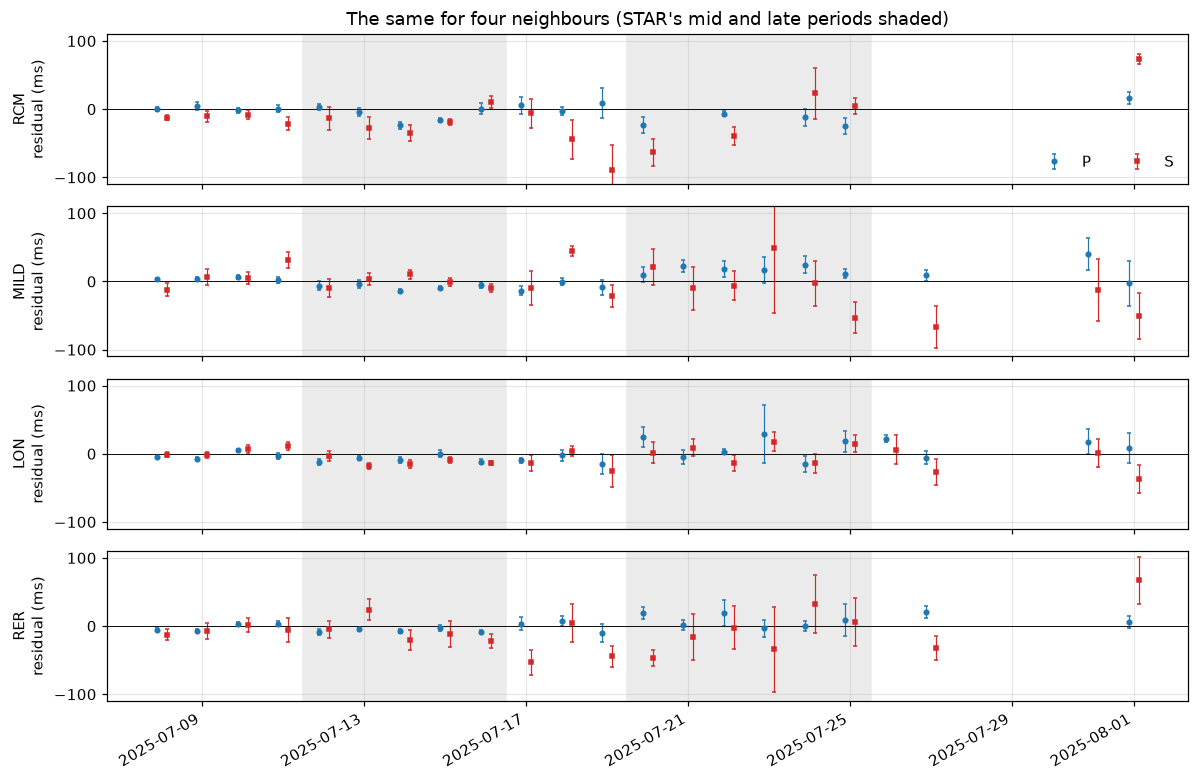

In [6]:
fig, axes = plt.subplots(len(STATIONS) - 1, 1, figsize=(11, 7.2), sharex=True, sharey=True)
for ax, s in zip(axes, STATIONS[1:]):
    x = daily[s]
    ax.errorbar(x.index - half, 1000 * x.res_p, yerr=1000 * x.se_p, fmt="o", ms=3, color="tab:blue", lw=0.8, capsize=1.5, label="P")
    ax.errorbar(x.index + half, 1000 * x.res_s, yerr=1000 * x.se_s, fmt="s", ms=3, color="tab:red", lw=0.8, capsize=1.5, label="S")
    ax.axhline(0, color="k", lw=0.6)
    ax.set_ylabel(f"{s}\nresidual (ms)")
    shade_periods(ax)
    print(f"{s}: daily P from {1000 * x.res_p.min():+.0f} to {1000 * x.res_p.max():+.0f} ms (range {1000 * (x.res_p.max() - x.res_p.min()):.0f} ms)")
axes[0].set(ylim=(-110, 110), title="The same for four neighbours (STAR's mid and late periods shaded)")
axes[0].legend(loc="lower right", ncol=2, frameon=False)
fig.autofmt_xdate(); plt.tight_layout()

Over the same days the P residuals stay between -24 and +40 ms at all four (ranges of the daily medians 41, 54, 44 and 31 ms), and their S residuals scatter on their own rather than following P. The highest point, MILD's +40 ms, is a single day (31 July); STAR's climb lasts a week.

A sturdier number compares two multi-day periods instead of two days: the median of all of STAR's picks in the late high (20 to 25 July) minus the median in the mid-swarm low (12 to 16 July), with a 68 percent bootstrap interval over picks. The same two periods at the other stations show what an ordinary station did over the same time.

In [7]:
def late_minus_mid(r, station, col, n_boot=2000, seed=0):
    """Median residual of a station's picks in LATE minus that in MID, with a 68 percent bootstrap interval over picks."""
    day = r.origin_time
    x = r.loc[(r.station == station) & (day >= MID[0]) & (day < MID[1]), col].to_numpy()
    y = r.loc[(r.station == station) & (day >= LATE[0]) & (day < LATE[1]), col].to_numpy()
    if min(len(x), len(y)) < 3:
        return np.nan, np.nan, np.nan, len(x), len(y)
    rng = np.random.default_rng(seed)
    boots = [np.median(rng.choice(y, len(y))) - np.median(rng.choice(x, len(x))) for _ in range(n_boot)]
    lo, hi = np.percentile(boots, [16, 84])
    return np.median(y) - np.median(x), lo, hi, len(x), len(y)

change = {}
for s in STATIONS:
    row_ = {}
    for ph in "PS":
        est, lo, hi, n_mid, n_late = late_minus_mid(res, s, f"res_{ph.lower()}")
        change[(s, ph)] = (est, lo, hi)
        row_[f"{ph} change (ms)"] = f"{1000 * est:+.0f} ({1000 * lo:+.0f} to {1000 * hi:+.0f})"
    change[s] = dict(picks_mid=n_mid, picks_late=n_late, **row_)
pd.DataFrame({s: change[s] for s in STATIONS}).T.rename_axis("late minus mid, 68% interval")

,picks_mid,picks_late,P change (ms),S change (ms)
"late minus mid, 68% interval",,,,
STAR,358,84,+65 (+56 to +70),+55 (+47 to +61)
RCM,302,48,+3 (-2 to +7),+6 (-17 to +19)
MILD,368,64,+26 (+21 to +30),-7 (-22 to +8)
LON,392,71,+9 (+3 to +16),+12 (+7 to +19)
RER,262,54,+15 (+9 to +19),-8 (-23 to +8)


**Between the two periods STAR's residuals rose by 65 ms in P (68 percent interval 56 to 70) and 55 ms in S (47 to 61)**, from 358 and 84 picks. At the other four stations P changed by +3 to +26 ms and S did not follow it: MILD's P rose by 26 ms while its S fell by 7. Three caveats. The two periods were chosen by looking at STAR's curve, which favours a large difference. The late earthquakes were a little farther from STAR, which explains 13 to 15 ms of it (exercise 1). And the locations absorbed part of any clock error (section 2), which hides some of it. So the number to carry forward is: **STAR's residuals changed by about 50 to 60 ms, P and S together, during the swarm**: 65 ms in P and 55 in S as measured, 52 and 40 once the geometry is removed (exercise 1), each uncertain by about 7 ms from the picks and by more from the choice of periods.

Now the test day by day: for each station, regress the daily S residual on the daily P residual. A clock gives slope 1 and a high correlation; the earth gives a slope around 1.7; pure scatter gives nothing. (Ordinary regression with noise on the x-axis biases the slope toward zero, so a clock shows up as a slope somewhat below 1; the correlation is the more honest number.) The table gives 68 percent bootstrap intervals over days.

STAR: lag-1 autocorrelation 0.78 (P) and 0.50 (S), so N_eff = 10 of 22 days; 95% bootstrap interval of r over days 0.55 to 0.90; correlation of the day-to-day changes 0.14


,days,P range (ms),slope,slope_lo,slope_hi,r,r_lo,r_hi
STAR,22,103,0.76,0.63,0.89,0.75,0.65,0.84
RCM,17,41,0.79,-0.25,1.68,0.26,-0.09,0.57
MILD,21,54,-0.04,-0.33,0.30,-0.02,-0.16,0.13
LON,22,44,0.53,0.37,0.66,0.50,0.33,0.67
RER,20,31,-0.03,-0.56,0.83,-0.01,-0.20,0.25


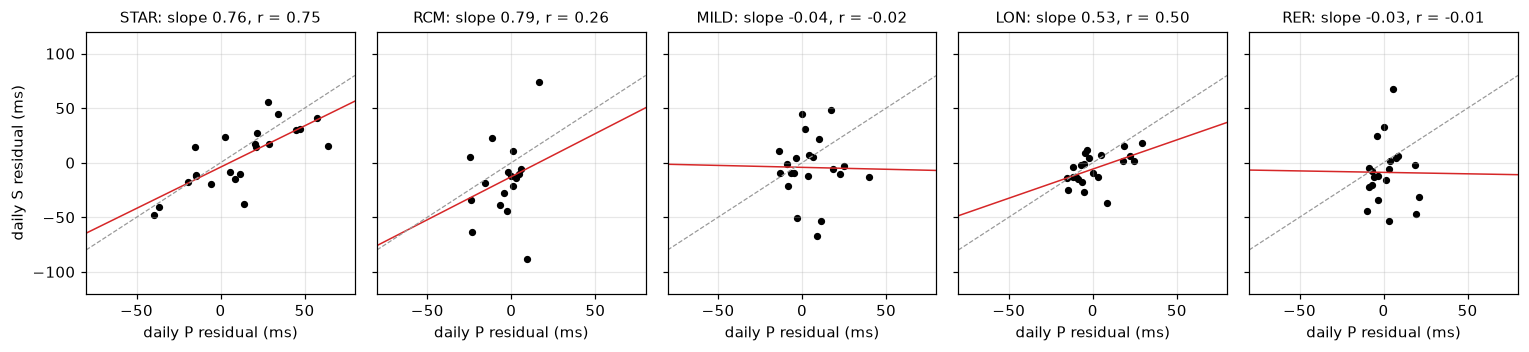

In [8]:
def p_s_stats(d, n_boot=1000):
    """Slope and correlation of daily S on daily P residuals, each with a 68 percent bootstrap interval over days."""
    p, s = d.res_p.to_numpy(), d.res_s.to_numpy()
    days = np.arange(len(p))
    sl = stats.bootstrap(days, lambda i: np.polyfit(p[i], s[i], 1)[0], n_boot=n_boot)
    r = stats.bootstrap(days, lambda i: np.corrcoef(p[i], s[i])[0, 1], n_boot=n_boot)
    return {"days": len(p), "P range (ms)": round(1000 * (p.max() - p.min())), "slope": sl[0], "slope_lo": sl[1],
            "slope_hi": sl[2], "r": r[0], "r_lo": r[1], "r_hi": r[2]}

fig, axes = plt.subplots(1, len(STATIONS), figsize=(14, 3.3), sharex=True, sharey=True)
rows = {}
for ax, s in zip(axes, STATIONS):
    x = daily[s]
    rows[s] = p_s_stats(x)
    slope, intercept = np.polyfit(x.res_p, x.res_s, 1)
    ax.scatter(1000 * x.res_p, 1000 * x.res_s, s=14, c="k")
    xx = np.array([-80, 80]); ax.plot(xx, slope * xx + 1000 * intercept, "tab:red", lw=1)
    ax.plot(xx, xx, "0.6", ls="--", lw=0.8)           # slope 1 = clock
    ax.set_title(f"{s}: slope {slope:.2f}, r = {rows[s]['r']:.2f}", fontsize=10); ax.set_xlabel("daily P residual (ms)")
axes[0].set_ylabel("daily S residual (ms)"); axes[0].set_xlim(-80, 80); axes[0].set_ylim(-120, 120)
plt.tight_layout()

p, s_ = daily["STAR"].res_p.to_numpy(), daily["STAR"].res_s.to_numpy()
rho_p, rho_s = np.corrcoef(p[:-1], p[1:])[0, 1], np.corrcoef(s_[:-1], s_[1:])[0, 1]
r95 = stats.bootstrap(np.arange(len(p)), lambda i: np.corrcoef(p[i], s_[i])[0, 1], n_boot=1000, ci=95)
print(f"STAR: lag-1 autocorrelation {rho_p:.2f} (P) and {rho_s:.2f} (S), so N_eff = {len(p) * (1 - rho_p * rho_s) / (1 + rho_p * rho_s):.0f} "
      f"of {len(p)} days; 95% bootstrap interval of r over days {r95[1]:.2f} to {r95[2]:.2f}; "
      f"correlation of the day-to-day changes {np.corrcoef(np.diff(p), np.diff(s_))[0, 1]:.2f}")
pd.DataFrame(rows).T.round(2).astype({"days": int, "P range (ms)": int})

STAR stands out: correlation 0.75 (0.65 to 0.84) and slope 0.76 (0.63 to 0.89), close to the dashed slope-1 line a clock would give. RCM has a similar slope but a correlation of only 0.26 (its S residuals are noisy); MILD and RER show none; LON has a weaker version, 0.50.

How much should 0.75 on 22 days convince you? Less than "22 points" suggests. Neighbouring days are not independent: the **lag-1 autocorrelation** (the correlation of each day with the next) is 0.78 for STAR's P residual and 0.50 for S, so the 22 days carry the information of about 10 independent ones (the **effective sample size** $N_\text{eff} = N(1 - \rho_P\rho_S)/(1 + \rho_P\rho_S)$ for two autocorrelated series, Bretherton et al., 1999), and the bootstrap over days, which treats them as independent, is optimistic (its 95 percent interval is 0.55 to 0.90). The day-to-day *changes* of P and S correlate at only 0.14: the co-movement is in the trend over several days, not in the daily wiggles. A slowly drifting clock would do exactly that (a day's drift of a few ms is buried in 3 to 30 ms of noise per daily median), but it means the evidence rests on a few multi-day swings.

Is STAR unique in the network? Of the 20 stations with at least 10 days, STAR has the largest P range and the strongest P-S correlation, but not by a wide margin on either: CRBN's P range is 84 ms (over only 10 days, correlation 0.57 with an interval from -0.28 to 0.82) and WOW's correlation is 0.72. Exercise 2 ranks them all; only STAR also moves P and S together between the mid and late periods.

The caveats, which are why this is "diagnostic 1" and not a conclusion:

- The travel-time model is one speed and straight rays. Paths to the summit station are the most unusual in the network, so STAR is also where model error is largest. The P-versus-S test guards against that, but only partly.
- PNSN used STAR's picks to locate these earthquakes, so the residuals show only the part of a clock error the locations could not absorb (section 2).
- S picks are noisier than P picks everywhere. S often begins as an **emergent** onset (the motion grows gradually out of the P coda, unlike an **impulsive** onset, which starts sharply), and analysts pick it on the horizontal channels. At STAR the channels labelled as horizontals were the true vertical and east (the exchange in `data.ORIENTATION_FIXES`, notebook 02).
- The swarm moved. If the earthquakes of late July were in a different place, the model error changes with time too. Exercise 1 removes the part of each residual that depends on distance and depth.

So the catalog says "STAR, July 2025, clock suspect: a change of about 50 to 60 ms". To turn that into a measurement you need data that does not depend on earthquakes, locations or analysts: diagnostic 2, sections 5 to 8. (Exercise 5 is halfway there: earthquakes, but no analyst.)

### If it is a clock, which clock?

The README says an analog station "means a fixed delay rather than a drift", and for the analog links themselves that is right: the McVCO, the radio and the discriminator delay the signal by fixed amounts. Three ways STAR's time could still wander, and the test for each:

- **The digitizer that samples STAR keeps time badly.** It lost GPS lock, or never had GPS and follows NTP over a busy network, and its oscillator wandered. Then every channel it digitizes wanders the same way, and any other station digitized by the same unit should show the same signature in diagnostic 1 at the same time.
- **The samples are re-stamped after digitizing**, by a computer that packages the data and stamps it with its own clock (the `PSNgw` at the end of STAR's chain might be such a gateway; the metadata do not say). The test is the same: which other stations go through it?
- **Not a clock at all**, but a change in the instrument's delay. STAR's whole instrument delay is about 45 ms at 10 Hz (section 2), so a 60 ms *change* would need the filters to more than double their delay. A change in the frequencies of the arrivals moves the effective delay too, but only by 13 ms between 5 and 10 Hz, and the band mix changed most between 8 and 10 July (notebook 03, exercise 3), not in late July.

Questions for PNSN, to write down for Michael: where is STAR's signal digitized today, and by what? How is that digitizer timed (GPS, NTP, something else), and is there a log of its GPS lock for July 2025? Which other stations go through the same digitizer or gateway? Did anything change in STAR's telemetry path between 1 July and 10 August 2025? And for the reference: is RCM digitized on site with GPS? No RCM StationXML is in this repo, so RCM's timing chain is unverified; diagnostic 1 says only that its P residual is steady.

## 4. How much does timing matter? The budget

The figure puts STAR's apparent clock change next to every other timescale that matters to the splitting measurement. Bars span the 10th to 90th percentile of STAR's values or a fixed range; open dots mark medians; filled dots are single values.

194 filtered STAR events: dt 0.02 to 0.08 s, median 0.06 s; daily-median standard errors 3 to 44 ms (10th to 90th percentile 5 to 26)


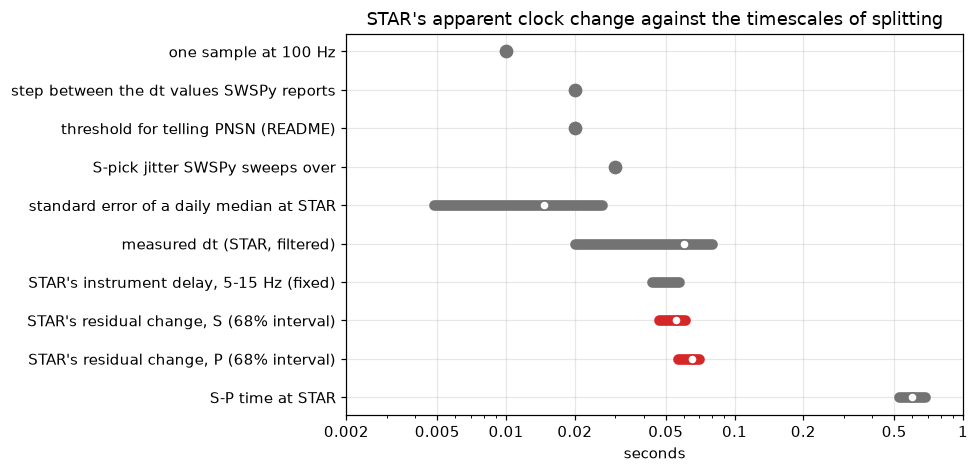

In [9]:
res_o = pd.read_csv(paths.station_results_csv("STAR", oriented=True))     # STAR, corrected components (notebook 07)
good = quality.post_filtered(res_o)
REPORT_THRESHOLD_S = 0.020          # README, winter item 1: a drift larger than this goes to PNSN and CVO
q = lambda x: (x.quantile(0.1), x.quantile(0.9), x.median())
gd = group_delay[(group_delay.index >= 5) & (group_delay.index <= 15)]
scales = [  # label, low, high, middle (None: a single value or a fixed range)
    ("one sample at 100 Hz", 0.01, 0.01, None),
    ("step between the dt values SWSPy reports", measure.dt_step(100.0), measure.dt_step(100.0), None),
    ("threshold for telling PNSN (README)", REPORT_THRESHOLD_S, REPORT_THRESHOLD_S, None),
    ("S-pick jitter SWSPy sweeps over", measure.SwsParams().s_pick_uncertainty, measure.SwsParams().s_pick_uncertainty, None),
    ("standard error of a daily median at STAR", *q(pd.concat([d.se_p, d.se_s]))),
    ("measured dt (STAR, filtered)", *q(good.dt)),
    ("STAR's instrument delay, 5-15 Hz (fixed)", gd.min(), gd.max(), None),
    ("STAR's residual change, S (68% interval)", change[("STAR", "S")][1], change[("STAR", "S")][2], change[("STAR", "S")][0]),
    ("STAR's residual change, P (68% interval)", change[("STAR", "P")][1], change[("STAR", "P")][2], change[("STAR", "P")][0]),
    ("S-P time at STAR", *q(star.ts - star.tp)),
]
fig, ax = plt.subplots(figsize=(9, 4.4))
for i, (label, lo, hi, mid) in enumerate(scales[::-1]):
    c = "tab:red" if label.startswith("STAR's residual") else "0.45"
    if lo == hi:
        ax.plot(lo, i, "o", color=c, ms=8)
    else:
        ax.plot([lo, hi], [i, i], color=c, lw=7, solid_capstyle="round")
    if mid is not None:
        ax.plot(mid, i, "o", color="w", mec=c, ms=6)
ax.set(xscale="log", xlim=(0.002, 1), yticks=range(len(scales)), yticklabels=[s[0] for s in scales[::-1]],
       xlabel="seconds", title="STAR's apparent clock change against the timescales of splitting")
ax.set_xticks([0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1])
ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%g")); ax.xaxis.set_minor_formatter(mticker.NullFormatter())
plt.tight_layout()
print(f"{len(good)} filtered STAR events: dt {good.dt.quantile(0.1):.2f} to {good.dt.quantile(0.9):.2f} s, median {good.dt.median():.2f} s; "
      f"daily-median standard errors {1000 * pd.concat([d.se_p, d.se_s]).min():.0f} to {1000 * pd.concat([d.se_p, d.se_s]).max():.0f} ms "
      f"(10th to 90th percentile {1000 * pd.concat([d.se_p, d.se_s]).quantile(0.1):.0f} to {1000 * pd.concat([d.se_p, d.se_s]).quantile(0.9):.0f})")

A clock change of about 50 to 60 ms is two and a half to three times the 20 ms at which PNSN should hear about it, as large as the splitting delays themselves, and about three steps of the grid SWSPy measures dt on. It is also bigger than the noise of the diagnostic that found it: the daily medians are uncertain by 3 to 44 ms, 5 to 26 ms for most days. And a *fixed* delay of the same size, STAR's instrument (44 to 57 ms at 5 to 15 Hz), does no harm at all. Whether a clock error matters depends on what it shifts relative to what:

| what the timing error shifts | what it does to the results | measured in |
| --- | --- | --- |
| all three channels and the picks together (an uncorrected clock, or a correction applied to both) | nothing to phi or dt: the measurement sees the same samples | section 1 |
| the waveforms but not the picks (a correction applied to the data only) | at 50 ms either way, 13 of 25 filtered events still pass the post-processing filter instead of 24, and dt changes for 5 to 7 of them | exercise 4 |
| one channel against another (a skew between the channels of an analog chain) | 10 to 30 ms turns phi by a median of 4 to 12 degrees and leaves 13 to 7 of 25 events in the filtered set instead of 24 | exercise 6 |
| the locations (STAR's picks are used to locate) | 50 ms puts the hypocentre a median of 190 m deeper, changes STAR's incidence angle by about 1 degree and percent anisotropy by about 4 percent of its value | section 2, exercise 7 |
| the network's common timescale | outliers in the phase-2 catalog; biased template matching and relative locations | section 1 |

So the honest summary for the project: a correction applied consistently to waveforms *and* picks changes the splitting results only through the locations, a small effect; a correction applied to the waveforms alone, or two systems with different clocks, changes them as much as the thresholds of notebook 07 do. The catalog and the cross-station methods are where a 60 ms error hurts most, which is why it goes to PNSN before the phase-2 catalog is built.

## 5. Ambient noise: a seismogram without an earthquake

The ground is never still. **Ambient noise** is everything a seismometer records between earthquakes: the ocean microseism below 0.5 Hz (notebook 03), and, in the 1 to 8 Hz band used here, wind, rivers and meltwater, glaciers cracking and sliding, rockfall, and people. Most of this energy travels as **surface waves**, waves trapped near the free surface whose motion fades with depth. They are slower than S waves, roughly 1 to 2 km/s in the shallow rock of a volcano, and their speed depends on frequency (low frequencies reach deeper, faster rock). There are two kinds:

- **Rayleigh waves** make the ground roll in a vertical ellipse in the direction of travel, so they show up on the vertical channel (and on the horizontal one pointing along the path).
- **Love waves** shake the ground sideways, horizontally and across the path, so the vertical channel does not see them.

That is why the recipe correlates vertical with vertical: Rayleigh waves only, one kind of wave with one speed at each frequency. (Notebook 07's "Rayleigh test" is a statistics test named after the same Lord Rayleigh; it has nothing to do with these waves.)

Now the key idea (Shapiro and Campillo, 2004). **Cross-correlate** the noise recorded at two stations, A and B: slide one record past the other and, at each **lag**, multiply and sum. A wave that passes A and then B shows up as a peak at a positive lag equal to its travel time from A to B; a wave going the other way gives a peak at the same negative lag. Average over enough noise, coming from enough directions, and the correlation converges to the **Green's function** between the stations: the seismogram B would record if you struck the ground at A with a hammer, on the **causal** side (positive lags), and its mirror image for a hammer at B on the **acausal** side (negative lags). In practice the two sides differ in strength, because the sources are not spread evenly (more glacier noise on one side of the pair, say).

What can move the packets? Two different things, and they move them differently (Stehly et al., 2007; Sens-Schönfelder, 2008):

- **A clock error at B** shifts B's whole record, so it shifts the *whole correlation*: both packets move the same way by the same amount.
- **A change in the rock** between A and B, a relative velocity change **dv/v**, changes the travel time in both directions alike: both packets move *away from* zero lag (slower rock) or toward it (faster rock), by opposite amounts. The correlation **stretches**.

  B's clock 30 ms late: causal +30.0 ms, acausal +30.0 ms -> half-sum (clock) +30.0 ms, half-difference (travel time)  +0.0 ms
        rock 1% slower: causal +30.3 ms, acausal -30.2 ms -> half-sum (clock)  +0.0 ms, half-difference (travel time) +30.3 ms


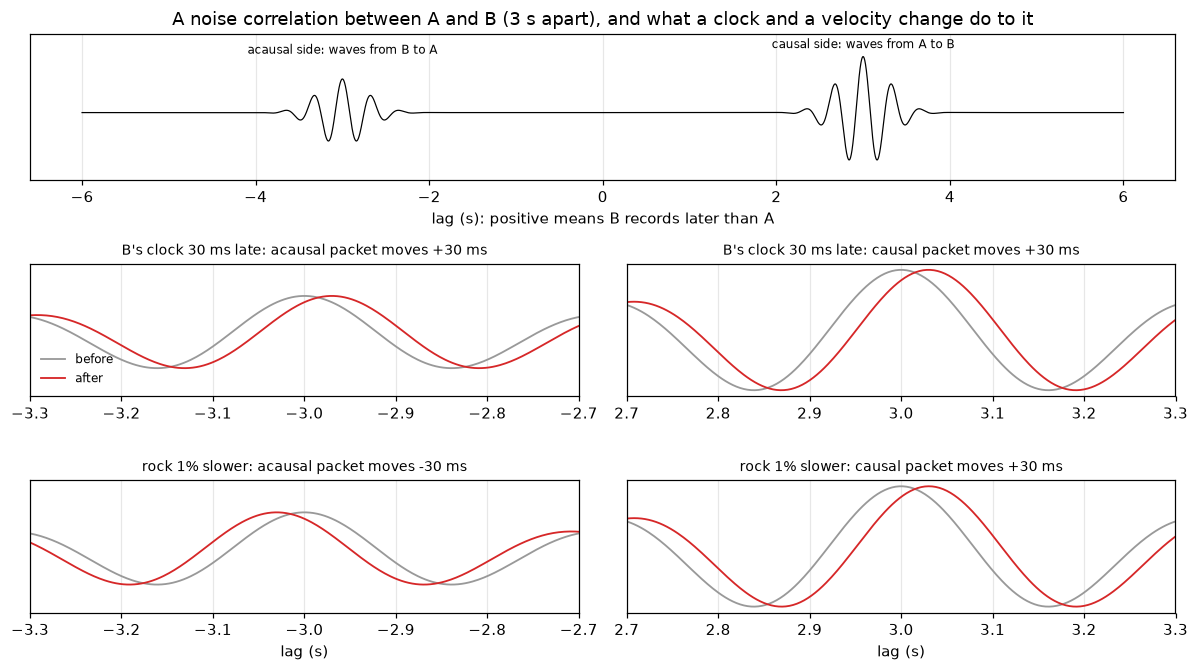

In [10]:
T_AB = 3.0         # s: a surface-wave travel time between two stations about 5 km apart (about 1.6 km/s)
F0 = 3.0           # Hz: centre frequency of the wave packet
CLOCK = 0.03       # s: station B's clock this late ...
DVV = -0.01        # ... or the rock between A and B this much slower (dv/v = -1 percent)
lag = np.arange(-6, 6.0001, 0.002)

def packet(t0):
    """A wave packet centred on lag t0 (a Gabor wavelet)."""
    return np.exp(-((lag - t0) * F0 / 1.2) ** 2) * np.cos(2 * np.pi * F0 * (lag - t0))

def two_sided(clock=0.0, dvv=0.0, causal=1.0, acausal=0.6):
    """A noise correlation with a packet on each side; the acausal one weaker (fewer sources on that side)."""
    T = T_AB / (1 + dvv)                       # travel time scales with 1 / velocity
    return causal * packet(T + clock) + acausal * packet(-T + clock)

ref = two_sided()
cases = {f"B's clock {1000 * CLOCK:.0f} ms late": two_sided(clock=CLOCK), f"rock {100 * -DVV:.0f}% slower": two_sided(dvv=DVV)}
fig = plt.figure(figsize=(11, 6.2))
gs = fig.add_gridspec(3, 2, height_ratios=[1.1, 1, 1])
ax = fig.add_subplot(gs[0, :])
ax.plot(lag, ref, "k", lw=0.8)
ax.text(-T_AB, 1.05, "acausal side: waves from B to A", ha="center", fontsize=8)
ax.text(T_AB, 1.15, "causal side: waves from A to B", ha="center", fontsize=8)
ax.set(xlabel="lag (s): positive means B records later than A", yticks=[], ylim=(-1.2, 1.4),
       title=f"A noise correlation between A and B ({T_AB:.0f} s apart), and what a clock and a velocity change do to it")
peaks = {}
for row, (name, cc) in enumerate(cases.items(), start=1):
    pos = timing.peak_lag(cc[None, :], lag, side="pos")[0]
    neg = timing.peak_lag(cc[None, :], lag, side="neg")[0]
    peaks[name] = (pos - T_AB, neg + T_AB)
    for col, centre in enumerate((-T_AB, T_AB)):
        a = fig.add_subplot(gs[row, col])
        a.plot(lag, ref, color="0.6", lw=1.2, label="before")
        a.plot(lag, cc, color="tab:red", lw=1.2, label="after")
        a.set(xlim=(centre - 0.3, centre + 0.3), yticks=[])
        moved = peaks[name][1 if centre < 0 else 0]
        a.set_title(f"{name}: {'acausal' if centre < 0 else 'causal'} packet moves {1000 * moved:+.0f} ms", fontsize=9)
        if row == 2:
            a.set_xlabel("lag (s)")
        if row == 1 and col == 0:
            a.legend(frameon=False, fontsize=8, loc="lower left")
plt.tight_layout()
for name, (d_pos, d_neg) in peaks.items():
    print(f"{name:>22}: causal {1000 * d_pos:+5.1f} ms, acausal {1000 * d_neg:+5.1f} ms -> half-sum (clock) "
          f"{1000 * (d_pos + d_neg) / 2:+5.1f} ms, half-difference (travel time) {1000 * (d_pos - d_neg) / 2:+5.1f} ms")

So from a two-sided correlation, half the sum of the two packets' shifts is the clock and half their difference is the travel time. Measure only one side and the two are indistinguishable: on the causal side both cases above move the packet by about +30 ms.

Does the rock change enough to matter? At volcanoes dv/v has been measured at about 0.05 percent before eruptions at Piton de la Fournaise (Brenguier et al., 2008) and of order 1 percent with the seasons and groundwater at Merapi (Sens-Schönfelder and Wegler, 2006). Over a surface-wave travel time of about 3 s, 0.1 to 1 percent is 3 to 30 ms: the size of the signal we are looking for, during a swarm driven by moving hydrothermal fluid, in July, with snowmelt and glacier noise at their peak. A changing noise source can also move the peak of one side on its own, because the packet only sits exactly at the travel time when the sources surround the pair evenly. So for STAR the rule is: **measure both sides**, and believe a clock only when they move together.

## 6. Diagnostic 2: the chronos method

If the earth between two stations does not change, and the noise sources do not change, the packets of their noise correlation stay at the same lags. If they move together (section 5), a clock moved. Everything else is signal processing to make the packets visible:

1. Cut the day into overlapping windows (chronos: 30 minutes, 7.5-minute step).
2. In each window, detrend, taper, **whiten** (flatten the amplitude spectrum inside a band, so that no single frequency dominates) and apply **one-bit normalization** (keep only the sign of each sample, so that an earthquake or a gust of wind cannot dominate). Both functions in `rainier_sws.timing` are imported from chronos when it is installed.
3. Cross-correlate the two windows (`cc_segment`; convention: positive lag means station b lags station a).
4. **Stack** by **median** over the windows that fall in each UTC hour: the median of the window correlations at each lag, rather than the mean, so that a few bad windows cannot pull the result.
5. Pick the lag of the maximum of the **envelope** of CC squared (`peak_lag`). The envelope is the smooth outline of a wave packet (the magnitude of its analytic signal; notebook 03, exercise 1). Squaring makes the pick insensitive to the sign of the wavelet; the envelope removes the oscillation inside the packet, so that the pick lands on the packet's centre rather than on one of its cycles. `peak_lag(..., side="pos")` or `side="neg"` restricts the search to one side of zero lag, as chronos' `--side` does. On real data pick both sides separately and form their half-sum and half-difference (section 5).
6. Clock error = peak lag minus the lag the pair *should* have, the **anchor**, taken from a period known to be good. Then an outlier filter (a rolling **Hampel filter**, from chronos: flag any hour further from the rolling median than a few times the rolling **MAD**, the median absolute deviation, a robust standard deviation), a jump detector, smoothing inside each stable segment between jumps, and finally chronfix resamples the raw data onto the true UTC grid with that model.

Two limits to remember. Resolution in lag is one sample: 0.125 s for chronos' 8 Hz ocean-bottom data, 10 ms at 100 Hz. chronos keeps the nearest-sample pick (its drifts are tens of seconds) and uses the curvature of a three-point parabola only for the error bar; we need tens of milliseconds, so `peak_lag` also moves the pick to the parabola's vertex. And resolution in time is one hour, because that is what the stack needs: a jump is only ever located to the hour, and an hourly value really describes the middle of its hour.

## 7. Try it where the answer is known

`timing.synthetic_pair` makes two stations recording the same band-limited noise field. Station A has a perfect clock. Station B records the same signal 1.2 s later (the inter-station travel time) and then **re-stamps it with a clock error you choose**, before independent noise is added to both. We choose a slow drift of 2 ms per hour for 40 hours, then a resync jump of 100 ms, then slower drift.

How strong the shared signal is, is set by `synthetic_pair`'s `snr` argument: the RMS of the shared signal over the RMS of each station's own noise. Call it the **coherent ratio**, to keep it apart from notebook 03's S-wave SNR, which is a different thing. At 0.7 the shared signal is weaker than the noise in every sample. The synthetic noise travels from A to B only, so its correlation has a causal packet and no acausal one; real noise gives both.

2 Trace(s) in Stream:
XX.REFA..HHZ | 2025-07-10T00:00:00.000000Z - 2025-07-12T23:59:59.950000Z | 20.0 Hz, 5184000 samples
XX.STAB..HHZ | 2025-07-10T00:00:00.000000Z - 2025-07-12T23:59:59.950000Z | 20.0 Hz, 5184000 samples


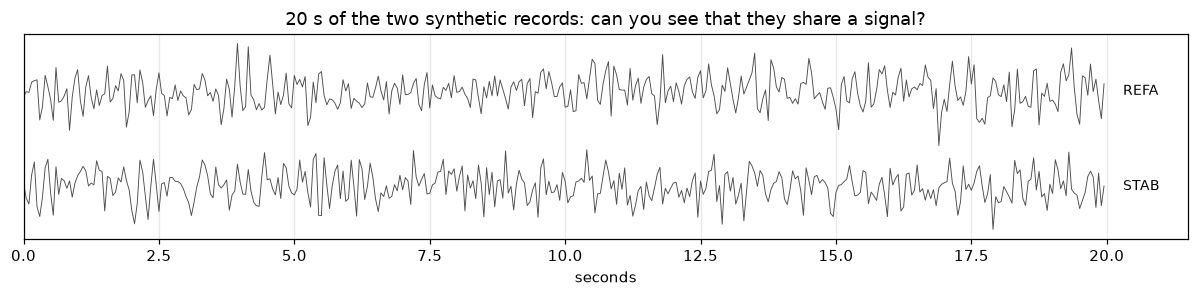

In [11]:
LAG_TRUE = 1.2          # s: the synthetic inter-station travel time
COHERENT_RATIO = 0.7    # RMS of the shared signal over RMS of each station's own noise (synthetic_pair calls it snr)

def true_delta_t(t_seconds):
    h = np.asarray(t_seconds, float) / 3600.0
    return np.where(h < 40, 0.002 * h, -0.02 + 0.0005 * (h - 40))      # seconds, positive = clock late

st, truth = timing.synthetic_pair(hours=72, fs=20.0, lag_s=LAG_TRUE, delta_t_fn=true_delta_t, snr=COHERENT_RATIO, seed=1)
print(st)
fig, ax = plt.subplots(figsize=(11, 2.8))
for tr, off in zip(st, (10, 0)):
    ax.plot(tr.times()[:400], tr.data[:400] + off, lw=0.6, color="0.3")
    ax.text(20.3, off, tr.stats.station, va="center", fontsize=9)
ax.set(xlim=(0, 21.5), xlabel="seconds", yticks=[], title="20 s of the two synthetic records: can you see that they share a signal?")
plt.tight_layout()

You cannot see the shared signal by eye. Cross-correlate every 10-minute window and look at the windows as an image, one row per window; then stack by hour. One number says how clearly a correlation shows its packet: the **peak-to-RMS ratio**, the largest value near the packet over the RMS of the correlation far from it. It can be computed on real stacks as well, which is what makes it useful (exercise 3).

1725 windows -> 72 hourly stacks; lag axis -10.0 to 10.0 s in steps of 0.05 s
peak-to-RMS ratio: median 20 for one window, 62 for an hourly stack


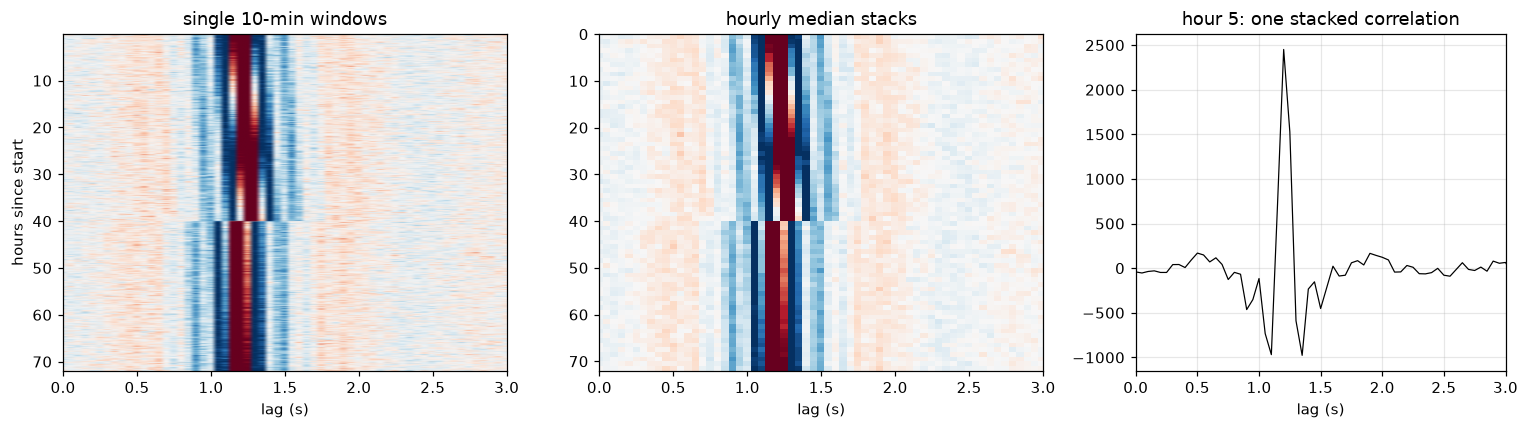

In [12]:
a, b, fs, t0 = timing.align_pair(st[0], st[1])
params = timing.CCParams()          # 10-minute windows, 2.5-minute step, whitening 1-6 Hz, lags to +-10 s
cc, mids, lags = timing.ccf_windows(a, b, fs, params)
cc_h, hours = timing.stack_by_hour(cc, mids, t0)
print(cc.shape[0], "windows ->", cc_h.shape[0], "hourly stacks; lag axis", lags[0], "to", lags[-1], "s in steps of", round(lags[1] - lags[0], 3), "s")

def peak_to_rms(cc_h, lags, expected, near_s=1.0, far_s=2.0):
    """How clearly each stack shows its packet: the largest |CC| within near_s of the expected lag over the RMS
    of the stack farther than far_s from it."""
    near, far = np.abs(lags - expected) <= near_s, np.abs(lags - expected) > far_s
    return np.nanmax(np.abs(cc_h[:, near]), axis=1) / np.sqrt(np.nanmean(cc_h[:, far] ** 2, axis=1))

print(f"peak-to-RMS ratio: median {np.median(peak_to_rms(cc, lags, LAG_TRUE)):.0f} for one window, "
      f"{np.median(peak_to_rms(cc_h, lags, LAG_TRUE)):.0f} for an hourly stack")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"width_ratios": [1.2, 1.2, 1]})
v = np.nanpercentile(np.abs(cc), 99)
axes[0].imshow(cc, aspect="auto", extent=[lags[0], lags[-1], mids[-1] / 3600, mids[0] / 3600], cmap="RdBu_r", vmin=-v, vmax=v)
axes[0].set_title("single 10-min windows"); axes[0].set_xlabel("lag (s)"); axes[0].set_ylabel("hours since start")
v = np.nanpercentile(np.abs(cc_h), 99)
axes[1].imshow(cc_h, aspect="auto", extent=[lags[0], lags[-1], len(hours), 0], cmap="RdBu_r", vmin=-v, vmax=v)
axes[1].set_title("hourly median stacks"); axes[1].set_xlabel("lag (s)")
for ax in axes[:2]: ax.set_xlim(0, 3); ax.grid(False)
axes[2].plot(lags, cc_h[5], "k", lw=0.8); axes[2].set_xlim(0, 3); axes[2].set_title("hour 5: one stacked correlation"); axes[2].set_xlabel("lag (s)")
plt.tight_layout()

At this coherent ratio the packet near 1.2 s is already visible in single 10-minute windows (each holds 12,000 samples), with a median peak-to-RMS ratio of 20; the hourly median stack raises that to 62 and makes the packet steady. You can see it lean to larger lags as the hours go by (B's clock running late pushes B's copy of the signal to later stamped times), then snap back at hour 40. Now pick it.

nearest sample  median |error|  12.9 ms   p90  21.0 ms   max  25.0 ms
refined         median |error|   3.6 ms   p90   5.5 ms   max   6.2 ms


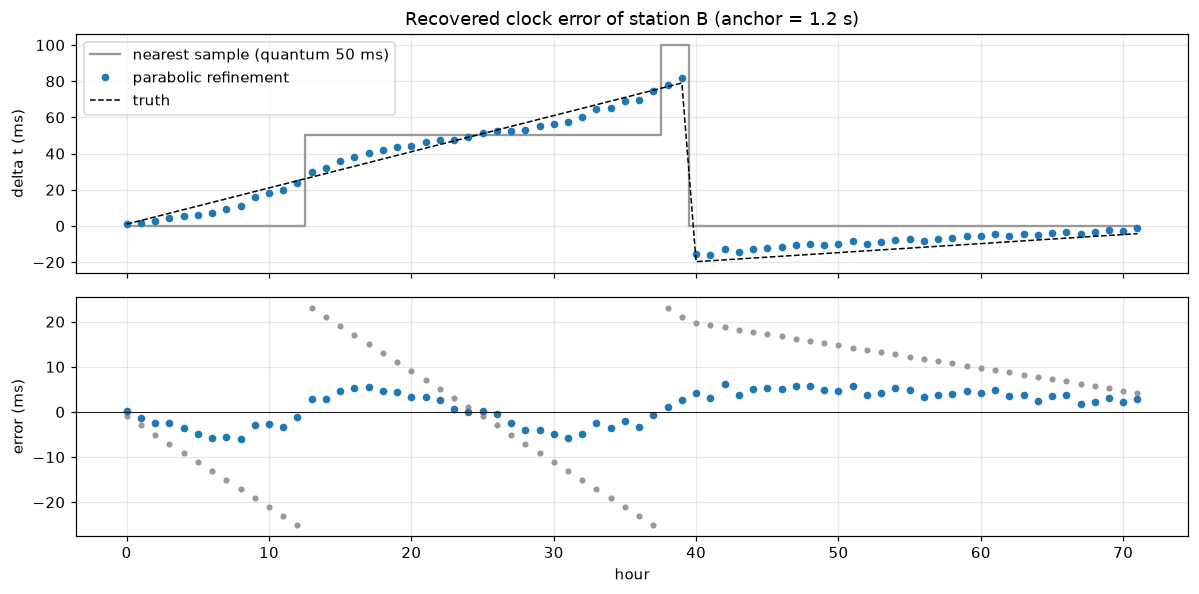

In [13]:
peak_nearest = timing.peak_lag(cc_h, lags, refine=False)
peak = timing.peak_lag(cc_h, lags, refine=True)
dt_nearest, _ = timing.delta_t_from_lags(peak_nearest, anchor=LAG_TRUE)
dt_est, anchor = timing.delta_t_from_lags(peak, anchor=LAG_TRUE)
hrs = np.arange(len(hours))

fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
axes[0].step(hrs, 1000 * dt_nearest, where="mid", color="0.6", label=f"nearest sample (quantum {1000/fs:.0f} ms)")
axes[0].plot(hrs, 1000 * dt_est, "o", ms=4, color="tab:blue", label="parabolic refinement")
axes[0].plot(hrs, 1000 * truth, "k--", lw=1, label="truth")
axes[0].set_ylabel("delta t (ms)"); axes[0].legend(loc="upper left"); axes[0].set_title(f"Recovered clock error of station B (anchor = {LAG_TRUE} s)")
axes[1].plot(hrs, 1000 * (dt_nearest - truth), ".", color="0.6"); axes[1].plot(hrs, 1000 * (dt_est - truth), "o", ms=4, color="tab:blue")
axes[1].axhline(0, color="k", lw=0.6); axes[1].set_ylabel("error (ms)"); axes[1].set_xlabel("hour")
plt.tight_layout()
for name, est in (("nearest sample", dt_nearest), ("refined", dt_est)):
    e = np.abs(est - truth)
    print(f"{name:<15} median |error| {1000*np.nanmedian(e):5.1f} ms   p90 {1000*np.nanpercentile(e, 90):5.1f} ms   max {1000*np.nanmax(e):5.1f} ms")

With 20 Hz data the nearest-sample picker can only answer in steps of 50 ms, the size of the whole signal. The parabola through three envelope samples gets the error down to a few milliseconds (median 3.6 ms, at most 6.2). That is the power of stacking, and the reason chronos works at all on 8 Hz ocean-bottom data.

Look at the error panel before moving on: it is not random. It is a sawtooth with a period of one sample, because a parabola is only an approximation to the envelope's shape and is biased toward the nearest sample. The cure is either a higher sampling rate (at 100 Hz the sawtooth is about 1 ms) or a better interpolator (sinc); the error bar chronos computes from the same parabola does not know about this bias, which is worth remembering when you report one.

Now a simplified version of the chronos post-processing: one Hampel outlier filter pass (chronos runs several, with a continuity check), jump (trigger) detection between retained samples, a rolling median inside each stable segment (chronos: a slope test, then a 24-hour rolling median and a 6-hour moving average), and a `ClockModel` that chronfix can apply. The cell uses the defaults of `timing.clean_delta_t` and `timing.smooth_segments`.

0 outlier hours removed; trigger (jump) at hours [39 40]; largest hour-to-hour step away from the jump 6.1 ms


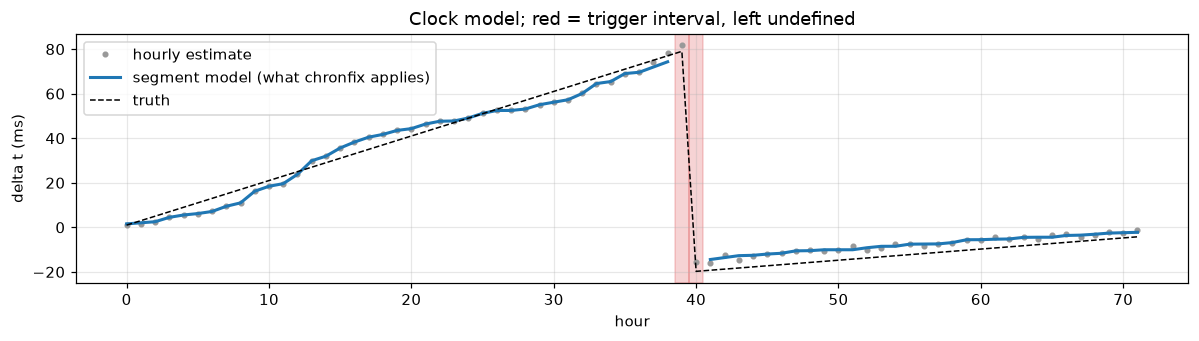

In [14]:
dt_clean, outliers, trig = timing.clean_delta_t(dt_est)          # the defaults: a 25-hour Hampel window, 3.5 sigma, jumps > 50 ms
dt_model = timing.smooth_segments(dt_clean, trig)                  # a 5-hour rolling median inside each segment
print(f"{outliers.sum()} outlier hours removed; trigger (jump) at hours {np.where(trig)[0]}; "
      f"largest hour-to-hour step away from the jump {1000 * np.max(np.delete(np.abs(np.diff(dt_est)), [38, 39, 40])):.1f} ms")

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.plot(hrs, 1000 * dt_est, ".", color="0.6", label="hourly estimate")
ax.plot(hrs, 1000 * dt_model, "-", color="tab:blue", lw=2, label="segment model (what chronfix applies)")
ax.plot(hrs, 1000 * truth, "k--", lw=1, label="truth")
for h in np.where(trig)[0]: ax.axvspan(h - 0.5, h + 0.5, color="tab:red", alpha=0.2)
ax.set_xlabel("hour"); ax.set_ylabel("delta t (ms)"); ax.legend(loc="upper left"); ax.set_title("Clock model; red = trigger interval, left undefined")
plt.tight_layout()

The default jump threshold, 50 ms, sits well above the ordinary hour-to-hour steps of this track (at most 6.1 ms away from the jump) and below the jump itself, so it finds the jump and nothing else. On STAR's track, choose it the same way: above the largest ordinary step, below the smallest jump you need to catch. A false trigger splits the record and leaves an hour uncorrected; a missed one lets the smoothing ramp across a real jump.

Why not apply the hourly estimates directly? chronos found out the hard way (its `issue1.md` is worth reading): the raw hourly track is a staircase of picker quanta, and interpolating a staircase into a per-sample correction injects a sub-second *false* time warp into every window. Smoothing each stable segment first fixed it. Trigger hours are left undefined, and the corrected output is split there: the clock really was discontinuous.

Apply the model with chronfix (per-sample resampling of B onto the true UTC grid), then close the loop: cross-correlate the corrected B against A and check that the peak lag is flat.

ClockModel(station='STAB', n_hours=74, n_valid=74, n_triggers=1)


2 Trace(s) in Stream:
XX.STAB..HHZ | 2025-07-10T00:00:00.998445Z - 2025-07-11T14:59:58.898445Z | 20.0 Hz, 2807959 samples
XX.STAB..HHZ | 2025-07-11T17:00:00.014439Z - 2025-07-12T23:59:57.964439Z | 20.0 Hz, 2231960 samples


segment 0: residual clock error after correction, median 1.0 ms, MAD 1.3 ms, n = 39 h


segment 1: residual clock error after correction, median -2.3 ms, MAD 0.6 ms, n = 31 h


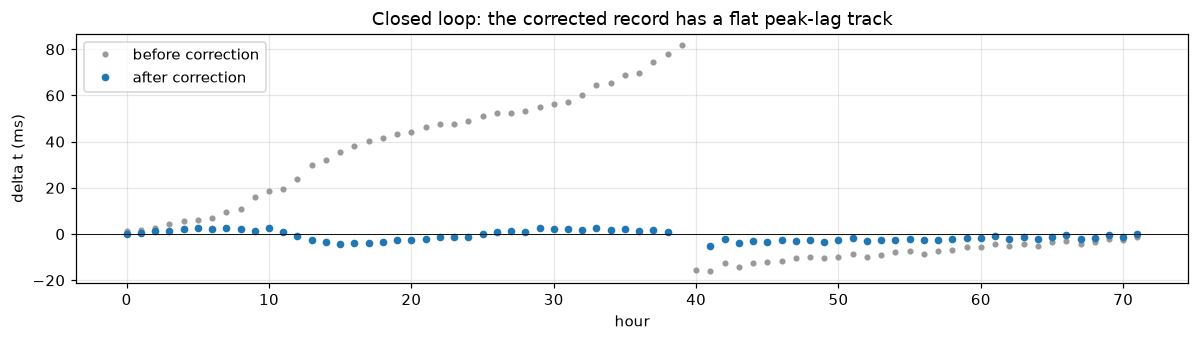

In [15]:
if timing.CHRONOS_AVAILABLE:
    model = timing.clock_model(hours, dt_model, trig, station="STAB")
    print(model)
    corrected = timing.correct_with_model(st.select(station="STAB"), model)
    print(corrected)

    fig, ax = plt.subplots(figsize=(11, 3.2))
    ax.plot(hrs, 1000 * dt_est, ".", color="0.6", label="before correction")
    for i, tr in enumerate(corrected):
        a2, b2, fs2, t02 = timing.align_pair(st[0], tr)
        d2 = timing.run_pair(a2, b2, fs2, t02, params)
        dt2, _ = timing.delta_t_from_lags(d2.peak_lag_s.values, anchor=LAG_TRUE)
        h2 = (d2.hour.values - hours[0]) / np.timedelta64(1, "h")
        ax.plot(h2, 1000 * dt2, "o", ms=4, color="tab:blue", label="after correction" if i == 0 else None)
        print(f"segment {i}: residual clock error after correction, median {1000*np.nanmedian(dt2):.1f} ms, MAD {1000*np.nanmedian(np.abs(dt2-np.nanmedian(dt2))):.1f} ms, n = {len(dt2)} h")
    ax.axhline(0, color="k", lw=0.6); ax.set_xlabel("hour"); ax.set_ylabel("delta t (ms)"); ax.legend(loc="upper left")
    ax.set_title("Closed loop: the corrected record has a flat peak-lag track")
    plt.tight_layout()
else:
    print("chronfix is not installed in this environment; see environment.yml. The correction step is skipped.")

A millisecond or two is left: pick noise, plus a small systematic piece, because an hourly estimate describes the middle of its hour but is stamped at its start (half an hour of drift at 2 ms per hour is 1 ms). One detail hides in `timing.align_pair`: after correction B's first sample no longer falls on a whole-sample boundary of A's grid, and if you simply trim both traces "to the same time" the correlation inherits that fraction-of-a-sample offset as a bias. chronos met the full-size version of this mistake while validating its own correction: its loader dropped the trace start time altogether, so the corrected data were re-misaligned by the whole delta t and the correction appeared to do nothing (method doc, section 10). `align_pair` interpolates onto a common grid instead.

## 8. Doing it for real: STAR

What changes with real data:

- **A reference station with trusted timing.** The nearest permanent three-component station is RCM (Camp Muir, 4.9 km from STAR, 3077 m), and diagnostic 1 says its P residual is steady, though its timing chain is not documented here (section 3). For the swarm itself there is something better: the Z5 nodal array (240 GPS-timed nodes, mid-July to mid-August 2025). Nodes 227 and 129 sit near Camp Muir, 5.2 to 5.7 km from STAR, and the node closest to the summit on the west side (node 44) is 6.6 km away. Ask Michael for access to those data; `fetch_continuous` works unchanged on them once they are on EarthScope or on disk. The nodes start after the swarm did, so RCM is still needed for early July.
- **The dates.** STAR's residuals climb between mid and late July (section 3), so the run has to cover the whole swarm and a quiet stretch before it for the anchor: 1 July to 2 August. That is about 1 GB of two 100 Hz channels, so the cell works one day at a time and keeps each finished day in `data/timing/`.
- **The band and the window.** At 5 km on a volcano the coherent noise is at higher frequency than in chronos' ocean-bottom case: whiten 1 to 8 Hz, use 10-minute windows, and **decimate** to 50 Hz (lower the sampling rate, after a low-pass filter so that nothing aliases; the lag quantum becomes 20 ms before refinement). If the hourly stacks show no stable packet, try 0.5 to 2 Hz and 30-minute windows; glacier and river noise is strong on Rainier and may give a clear packet where you least expect it.
- **Both sides.** Pick the causal and the acausal packet separately; their half-sum is STAR's clock and their half-difference the RCM-STAR travel time (section 5). `timing.run_pair` returns only the global maximum, so the cell keeps its hourly stacks and picks each side with `peak_lag(..., side=...)`. If one side never shows a clear packet, fall back to the other and say that a clock and a velocity change cannot then be told apart.
- **The anchor.** You do not know the true inter-station lag. chronos takes the median over a period believed to be good; here, the days before the swarm began on 8 July. An anchor error is a constant offset, which never matters for a drift.
- **The right channel.** STAR's vertical is the channel labelled `EHN` (notebook 02); `EHZ` records north. A "Z-Z" correlation on the labels would correlate STAR's north with RCM's vertical and mix Love and Rayleigh waves, so the cell takes STAR's vertical from `data.ORIENTATION_FIXES`.
- **Gaps.** `fetch_continuous` zero-fills and tapers gaps the way chronos does; a window that is all zeros is skipped.

The cell needs EarthScope (notebook 00 tells you whether you have it), so it is switched off by default. STAR's **location code**, the two-character label that separates instruments at one site, is `01`, so the request uses location `*` (requesting the blank location code returns nothing, which once made the research repo believe STAR had no archived data at all). RCM carries more than one channel code; `fetch_continuous` keeps the longest matching trace and says which.

In [16]:
from dataclasses import replace
from obspy import UTCDateTime
RUN_LIVE = False      # set True on a machine that can reach EarthScope; about 1 GB of downloads, an hour or more
LIVE_START, LIVE_END = UTCDateTime(2025, 7, 1), UTCDateTime(2025, 8, 2)   # 1-7 July is before the swarm (the anchor)
SWARM_START = np.datetime64("2025-07-08T08", "h")                          # 01:29 PDT on 8 July is 08:29 UTC
LIVE_FS = 50.0                                     # Hz after decimation: lag quantum 20 ms before refinement
live = replace(timing.CCParams(), whiten_fmax=8.0) # whiten 1-8 Hz for a 5-km summit pair (the synthetic used 1-6 Hz)
STAR_VERTICAL = next(ch for (net, s, loc, ch), (az, dip) in data.ORIENTATION_FIXES.items() if s == "STAR" and dip == -90)
out = paths.DATA / "timing"
print(f"STAR's true vertical is the channel labelled {STAR_VERTICAL} (data.ORIENTATION_FIXES)")
if RUN_LIVE:
    out.mkdir(exist_ok=True)
    day_files = []
    for k in range(int((LIVE_END - LIVE_START) // 86400)):
        t0_ = LIVE_START + 86400 * k
        f = out / f"cc_hourly_RCM-STAR_{t0_.strftime('%Y-%m-%d')}.npz"
        if not f.exists():                           # one day at a time; a finished day is kept, so a rerun resumes
            star_tr = timing.fetch_continuous("UW", "STAR", t0_, t0_ + 86400, channel=STAR_VERTICAL, target_fs=LIVE_FS)
            rcm_tr = timing.fetch_continuous("UW", "RCM", t0_, t0_ + 86400, channel="?HZ", target_fs=LIVE_FS)
            a_, b_, fs_, ts_ = timing.align_pair(rcm_tr, star_tr)        # a = reference (RCM), b = target (STAR)
            day_ = timing.run_pair(a_, b_, fs_, ts_, live)              # hourly stacks; ignore its one global peak column
            np.savez(f, hour=day_.hour.values.astype("datetime64[h]"), cc=day_.attrs["cc_hourly"],
                     lags=day_.attrs["lags"], n_windows=day_.n_windows.values)
        day_files.append(np.load(f))
    hours_live = np.concatenate([z["hour"] for z in day_files])
    cc_live, lags_live = np.vstack([z["cc"] for z in day_files]), day_files[0]["lags"]
    lag_pos = timing.peak_lag(cc_live, lags_live, side="pos")            # waves from RCM to STAR
    lag_neg = timing.peak_lag(cc_live, lags_live, side="neg")            # waves from STAR to RCM
    clock = (lag_pos + lag_neg) / 2                                     # both sides move together: a clock
    travel = (lag_pos - lag_neg) / 2                                    # the sides move apart: the travel time
    before = hours_live < SWARM_START
    dt_star, anchor_live = timing.delta_t_from_lags(clock, anchor=np.nanmedian(clock[before]), target_is_b=True)
    ptr = peak_to_rms(cc_live, lags_live, np.nanmedian(lag_pos[before]))
    pd.DataFrame({"hour": hours_live, "lag_pos_s": lag_pos, "lag_neg_s": lag_neg, "star_delta_t_s": dt_star,
                  "travel_time_change_s": travel - np.nanmedian(travel[before]), "peak_to_rms": ptr}
                 ).to_csv(out / "delta_t_RCM-STAR_2025-07.csv", index=False)
    fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
    axes[0].plot(hours_live, 1000 * dt_star, "o", ms=2, color="tab:red"); axes[0].set_ylabel("STAR delta t (ms)\n(half-sum)")
    axes[1].plot(hours_live, 1000 * (travel - np.nanmedian(travel[before])), "o", ms=2, color="0.4")
    axes[1].set_ylabel("travel-time change (ms)\n(half-difference)")
    axes[2].plot(hours_live, ptr, "o", ms=2, color="0.4"); axes[2].set(ylabel="peak-to-RMS", yscale="log")
    axes[0].set_title(f"RCM-STAR, anchor (half-sum before the swarm) {anchor_live:.3f} s")
    fig.autofmt_xdate(); plt.tight_layout()
else:
    print("RUN_LIVE is False: skipping the EarthScope download. The code above is the whole recipe.")

STAR's true vertical is the channel labelled EHN (data.ORIENTATION_FIXES)
RUN_LIVE is False: skipping the EarthScope download. The code above is the whole recipe.


When you have a real track, four things to do with it, in order:

1. Check the stacks first: their peak-to-RMS ratio (bottom panel) says whether an hourly value can be trusted (exercise 3 calibrates it). Average hours where it is low.
2. Overlay the half-sum on the daily residuals of diagnostic 1 (same sign convention: positive means STAR's clock is late, so its picks are late, so its P residual is positive). If they agree in shape, you have measured the clock. If the half-difference moves instead, the rock or the noise sources changed, which is a finding of its own. If they disagree, say so; both diagnostics have assumptions and the disagreement is the finding.
3. If the drift is bigger than about 20 ms, tell Michael. PNSN and CVO need to know, and the phase-2 catalog must not be built on uncorrected STAR data.
4. Build the `ClockModel`, run `timing.correct_with_model` on the cached STAR event windows, apply the same correction to STAR's picks (they were made on the uncorrected records, so they carry the same clock error), and re-run notebook 05 on a few events with the corrected waveforms and corrected picks. The splitting measurements should then change by exactly nothing (the same shift on all three channels and on the picks) **unless** the pick-to-waveform alignment was the problem. Correcting the waveforms but keeping the old picks is a different experiment: it moves the S wave relative to every window placed from the pick, and that alone changes measurements (exercise 4 measures how much). That experiment is the "timing correction applied to the pipeline" item of the README's winter quarter.

## 9. Glossary

| term | meaning | section |
| --- | --- | --- |
| acausal, causal side | negative and positive lags of a noise correlation: waves travelling from B to A, and from A to B | 5 |
| ambient noise | ground motion recorded between earthquakes: ocean, wind, water, ice, people | 5 |
| analog FM telemetry | sending a sensor's voltage as a radio tone whose pitch follows it; STAR's link | 1 |
| anchor | the inter-station lag the pair should have, taken from a period believed good | 6 |
| associator | software that groups picks from many stations into earthquakes | 1 |
| bootstrap | uncertainty of a statistic from recomputing it on resamples drawn with replacement | 3 |
| coherent ratio | in the synthetic: RMS of the shared signal over RMS of each station's own noise | 7 |
| confounded | two possible causes that changed together, so a fit cannot tell them apart | 11 (ex. 1) |
| cross-correlation | slide one record past another, multiply and sum at each lag | 5 |
| decimate | lower the sampling rate, after a low-pass filter so nothing aliases | 8 |
| digitizer | the analog-to-digital converter that samples a voltage and stamps each sample with a time | 1 |
| discriminator | turns the pitch of a telemetry tone back into a voltage | 1 |
| double-difference relocation | locating earthquakes relative to each other from differences of their arrival times | 1 |
| drift, offset, jump (trigger) | a clock error growing smoothly, constant, and snapping back at a resynchronization | 1 |
| dv/v | relative change of seismic velocity; stretches a noise correlation | 5 |
| effective sample size | how many independent points an autocorrelated series is worth | 3 |
| emergent, impulsive onset | an arrival that grows gradually, and one that starts sharply | 3 |
| envelope | the smooth outline of a wave packet, the magnitude of its analytic signal | 6 |
| epicentre, epicentral distance | the point on the surface above the hypocentre, and the horizontal distance from it | 2 |
| GPS lock | a receiver with a fix on the GPS satellites, keeping a clock right to well under 1 ms | 1 |
| Green's function | the record at one station of an impulse at another | 5 |
| group delay | how late a filter makes a wave packet: minus the slope of its phase against angular frequency | 2 |
| Hampel filter | flags points further from a rolling median than a few rolling MADs | 6 |
| hypocentre, hypocentral distance | where the earthquake started (with its depth), and the straight line from it to the station | 2 |
| lag | the time shift between two records in a cross-correlation | 5 |
| lag-1 autocorrelation | the correlation of a series with itself one step later | 3 |
| locate (location) | find the hypocentre and origin time that best fit the picks | 2 |
| location code | two characters separating instruments at one site; STAR's is `01` | 8 |
| Love wave | a surface wave shaking the ground horizontally, across its path | 5 |
| LQT | the frame of the incoming ray, used to rotate the components (notebook 05) | 1 |
| MAD | median absolute deviation: a robust standard deviation | 6 |
| McVCO | the voltage-controlled oscillator of STAR's analog telemetry | 1 |
| NTP | network time protocol: setting a computer's clock over a network | 1 |
| one-bit normalization | keep only the sign of each sample | 6 |
| origin time | when the earthquake started | 2 |
| peak-to-RMS ratio | largest value of a correlation near its packet over its RMS far from it | 7 |
| pick, picker | the marked arrival time of a wave; software that makes picks | 2, 1 |
| Rayleigh wave | a surface wave rolling the ground in a vertical ellipse; seen on the vertical | 5 |
| residual | observed minus predicted travel time | 2 |
| slowness | 1 / speed, in s/km: the slope of travel time against distance | 2 |
| stack (median stack) | combine many correlations into one, here by the median at each lag | 6 |
| station term | one constant per station and phase for everything a travel-time model misses near the station | 2 |
| strict catalog | PNSN's reviewed swarm picks with both P and S at a station (notebook 02) | 2 |
| surface wave | a wave trapped near the free surface, slower than S | 5 |
| template matching | scanning continuous data with a known earthquake's waveform to find others | 1 |
| trade-off (depth, origin time) | a deeper source and an earlier origin time fit the picks almost equally well | 2 |
| travel time | arrival time minus origin time | 2 |
| Vp/Vs | ratio of P to S speed; S residuals from the earth are about this much larger than P | 2 |
| whitening | flattening the amplitude spectrum inside a band | 6 |

References in this notebook: Shelly, D.R., Moran, S.C. & Thelen, W.A. (2013), *Evidence for fluid-triggered slip in the 2009 Mount Rainier, Washington earthquake swarm*, GRL 40, 1506-1512, doi:10.1002/grl.50354. Kidiwela, M., chronos and chronfix, [github.com/MaleenKidiwela/chronos](https://github.com/MaleenKidiwela/chronos). Bretherton, C.S., Widmann, M., Dymnikov, V.P., Wallace, J.M. & Bladé, I. (1999), *The effective number of spatial degrees of freedom of a time-varying field*, J. Climate 12, 1990-2009. Shapiro, N.M. & Campillo, M. (2004), *Emergence of broadband Rayleigh waves from correlations of the ambient seismic noise*, GRL 31, L07614, doi:10.1029/2004GL019491. Stehly, L., Campillo, M. & Shapiro, N.M. (2007), *Traveltime measurements from noise correlation: stability and detection of instrumental time-shifts*, GJI 171, 223-230, doi:10.1111/j.1365-246X.2007.03492.x. Sens-Schönfelder, C. (2008), *Synchronizing seismic networks with ambient noise*, GJI 174, 966-970, doi:10.1111/j.1365-246X.2008.03842.x. Sens-Schönfelder, C. & Wegler, U. (2006), *Passive image interferometry and seasonal variations of seismic velocities at Merapi Volcano, Indonesia*, GRL 33, L21302, doi:10.1029/2006GL027797. Brenguier, F. et al. (2008), *Towards forecasting volcanic eruptions using seismic noise*, Nature Geoscience 1, 126-130, doi:10.1038/ngeo104.

## 10. Exercises

Each one answers a question the project needs answered before STAR's timing, or STAR's picks, can be trusted. Exercises 1 to 4 are the core; 5 to 7 are stretch exercises.

1. **Is the STAR signal real, or the swarm moving?** Before STAR's picks go into the phase-2 catalog, rule out the geometry. Regress each STAR pick's P and S residual on its epicentral distance and depth (all picks, one regression per phase; mind that the late events were also a little farther away), remove that part, and redo the daily residuals with error bars, the P-S regression and the late-minus-mid change. Does the signal survive?
2. **Which stations' timing is suspect?** Rank every station with at least 10 days of picks by the range of its daily P residual, the correlation of daily S with daily P (with its interval), and the late-minus-mid change in P and in S. Which stations, other than STAR, would you ask PNSN about?
3. **Can a 50 Hz RCM-STAR pair resolve 20 ms, and how long a stack does that take?** Use `synthetic_pair` at 50 Hz with a 3 s lag and a clock that wanders by ±30 ms, sweep the coherent ratio from 0.3 down to 0.07, and average 1, 2, 4 and 8 hourly stacks. Which share of the estimates is within 20 ms, with and without the parabolic refinement? Since the coherent ratio of the real pair is unknown, find the peak-to-RMS ratio of a stack above which its estimate can be trusted.
4. **Does a timing correction have to move the picks too?** Take 25 events from STAR's filtered set, re-stamp their waveforms by ±20 and ±50 ms while keeping the picks, and measure each again (`measure.measure_event`, with the stored incidence angle). How many still pass the post-processing filter, and how many change dt or phi?
5. (Stretch) **An analyst-free check of the clock.** For every event picked at both STAR and RCM, cross-correlate the P waves on the two vertical channels to get the RCM-minus-STAR arrival-time difference from the waveforms alone, and compare it with the difference of the picks. RCM's P windows are in `data/timing/rcm_p_windows.mseed`. Remove the geometry and look at the late-minus-mid change and the day-by-day agreement with STAR's P residual. Does the waveform difference confirm the picks?
6. (Stretch) **Could a skew inside STAR's analog chain bias phi?** Each channel of an analog station has its own VCO and discriminator, so in principle the channels can be delayed differently. Delay STAR's east channel by 1, 2 and 3 samples (10 to 30 ms) on the same 25 events and measure again. How large a skew would matter? (Notebook 03, exercise 5 did the same for mismatched geophones.)
7. (Stretch) **What does a STAR clock error do to the locations?** Relocate about 150 events with a straight-ray grid search (the `trial_residuals` of section 2, the fitted speeds and station terms) with STAR's picks as they are and 50 ms late. How far do the hypocentres move, and how much do STAR's incidence angle, back azimuth and hypocentral distance (and so percent anisotropy) change?

A note before you use chronfix on STAR, at the end of the solutions: a boundary case in chronfix that drops data next to a trigger, with a failing test you could send upstream.

Next: `05_single_event_with_swspy.ipynb`, the real measurement; keep the clock in mind when you get to section 6 (incidence angle).

## 11. Example solutions

One way to do each exercise. Try them yourself first. Exercises 4 and 6 measure 25 events five and three more times, and exercise 3 makes five synthetic pairs: about a minute or two each.

### Exercise 1: is the STAR signal real, or the swarm moving?

One trap first. The late events were also a little farther from STAR than the mid ones, so a fit of residual against distance over the whole swarm could mistake a clock for a distance effect, or the reverse: the two are **confounded**. A clock is the same for every pick of one day, so fit the dependence on distance and depth from the variation *within* each day (subtract each day's mean from the residuals and from the geometry first), where a clock cannot leak in. Then remove that dependence from every one of STAR's 1196 picks (none is thrown away), relative to the mean geometry, and redo section 3.

res_p: +42 ms per km of epicentral distance, -15 ms per km of depth
res_s: +43 ms per km of epicentral distance, -63 ms per km of depth
late minus mid: the earthquakes were +0.58 km farther from STAR and +0.17 km deeper (medians)


,P range (ms),slope,r,P late-mid (ms),S late-mid (ms)
"STAR, 68% intervals",,,,,
as in section 3,103,0.76 (0.63 to 0.89),0.75 (0.65 to 0.84),+65 (+56 to +70),+55 (+47 to +61)
distance and depth removed,93,0.86 (0.74 to 0.98),0.81 (0.73 to 0.88),+52 (+44 to +58),+40 (+33 to +49)


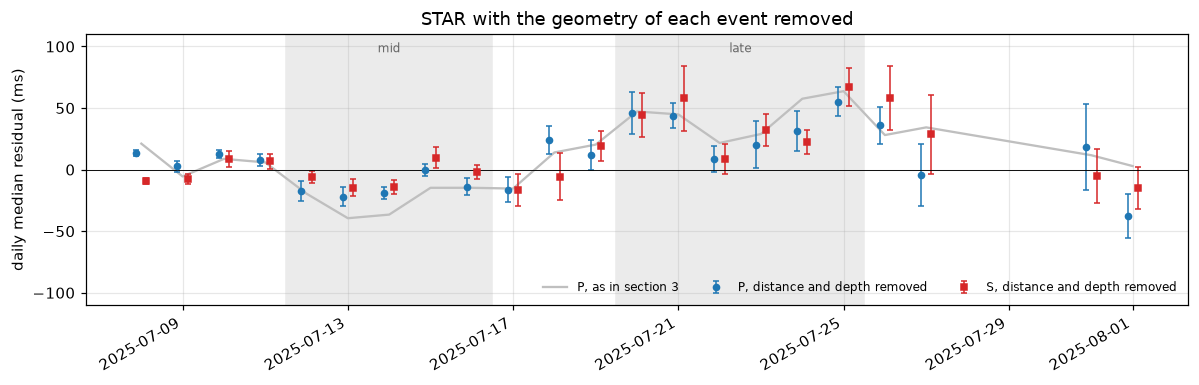

In [17]:
day_of = star.origin_time.dt.floor("D")
within_day = lambda v: v - v.groupby(day_of).transform("mean")   # what is left after each day's mean is removed
geom = star[["epi_km", "event_depth"]]
X = np.column_stack([within_day(geom.epi_km), within_day(geom.event_depth)])
star_geo = star.copy()
for col in ("res_p", "res_s"):
    b_, *_ = np.linalg.lstsq(X, within_day(star[col]).to_numpy(), rcond=None)
    star_geo[col] = star[col] - (geom - geom.mean()).to_numpy() @ b_     # remove the part that depends on distance and depth
    print(f"{col}: {1000 * b_[0]:+.0f} ms per km of epicentral distance, {1000 * b_[1]:+.0f} ms per km of depth")
late_ = (star.origin_time >= LATE[0]) & (star.origin_time < LATE[1]); mid_ = (star.origin_time >= MID[0]) & (star.origin_time < MID[1])
print(f"late minus mid: the earthquakes were {geom.epi_km[late_].median() - geom.epi_km[mid_].median():+.2f} km farther from STAR "
      f"and {geom.event_depth[late_].median() - geom.event_depth[mid_].median():+.2f} km deeper (medians)")
d_geo = timing.daily_residuals(star_geo, "STAR", n_boot=N_BOOT)

rows = {}
for name, r_, dd_ in (("as in section 3", star, daily["STAR"]), ("distance and depth removed", star_geo, d_geo)):
    x_ = p_s_stats(dd_)
    rows[name] = {"P range (ms)": x_["P range (ms)"], "slope": f"{x_['slope']:.2f} ({x_['slope_lo']:.2f} to {x_['slope_hi']:.2f})",
                  "r": f"{x_['r']:.2f} ({x_['r_lo']:.2f} to {x_['r_hi']:.2f})"}
    for ph in "PS":
        est, lo, hi, *_ = late_minus_mid(r_, "STAR", f"res_{ph.lower()}")
        rows[name][f"{ph} late-mid (ms)"] = f"{1000 * est:+.0f} ({1000 * lo:+.0f} to {1000 * hi:+.0f})"

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(daily["STAR"].index, 1000 * daily["STAR"].res_p, "-", color="0.75", lw=1.5, label="P, as in section 3")
ax.errorbar(d_geo.index - half, 1000 * d_geo.res_p, yerr=1000 * d_geo.se_p, fmt="o", ms=4, color="tab:blue", lw=1, capsize=2, label="P, distance and depth removed")
ax.errorbar(d_geo.index + half, 1000 * d_geo.res_s, yerr=1000 * d_geo.se_s, fmt="s", ms=4, color="tab:red", lw=1, capsize=2, label="S, distance and depth removed")
ax.axhline(0, color="k", lw=0.6); shade_periods(ax, label=True)
ax.set(ylabel="daily median residual (ms)", ylim=(-110, 110), title="STAR with the geometry of each event removed")
ax.legend(loc="lower right", frameon=False, fontsize=8, ncol=3)
fig.autofmt_xdate(); plt.tight_layout()
pd.DataFrame(rows).T.rename_axis("STAR, 68% intervals")

**The signal survives the geometry, at about 50 ms instead of 60.**

- Within days, the P residual grows by 42 ms per km of epicentral distance (S by 43) and falls by 15 ms per km of depth (S by 63): a real dependence, the straight-ray model's error for these paths. Between the mid and the late periods the earthquakes were 0.58 km farther from STAR and 0.17 km deeper (medians), so part of STAR's rise is the swarm moving.
- With the geometry removed event by event, the daily P residual ranges over 93 ms instead of 103, and P and S move together more tightly than before: correlation 0.81 (0.73 to 0.88) instead of 0.75, slope 0.86 (0.74 to 0.98), closer to the slope 1 of a clock. The late-minus-mid change shrinks from +65 to +52 ms in P (44 to 58) and from +55 to +40 ms in S (33 to 49).

So 13 ms of the late-July rise in P, and 15 in S, is the swarm moving away from STAR. The rest, about 50 ms in P and 40 in S, is not, and it moves P and S together more closely than the raw residuals do. (S changing a little *less* than P is the opposite of what a location or model error does, about 1.7 times more in S.) Answer to the project question: STAR's July 2025 picks carry an apparent timing change of about 50 ms, 40 to 65 ms depending on how it is measured. They should not go into the phase-2 catalog uncorrected until diagnostic 2 has been run.

### Exercise 2: which stations' timing is suspect?

`travel_time_residuals` already fitted every station in the strict catalog, so each station only needs its daily medians, the P-S statistics and the late-minus-mid change (over STAR's periods, which for every other station were fixed before looking at it). The table lists all of them, by the range of the daily P residual.

20 stations; besides STAR, P late minus mid from -26 to +26 ms, S from -74 to +75 ms


,picks,days,P range (ms),slope,r,r_lo,r_hi,picks late,P change,P lo,P hi,S change,S lo,S hi
STAR,1196.0,22.0,103.0,0.76,0.75,0.65,0.84,84.0,64.92,56.28,69.89,55.39,46.51,60.83
CRBN,148.0,10.0,84.0,0.63,0.57,-0.28,0.82,12.0,2.56,-5.34,14.94,17.43,-8.62,37.96
MILD,1016.0,21.0,54.0,-0.04,-0.02,-0.16,0.13,64.0,25.83,21.00,30.33,-6.86,-21.83,7.72
OPCH,129.0,11.0,49.0,0.48,0.35,0.07,0.55,9.0,-17.14,-28.49,1.30,-26.76,-35.81,-8.28
SIFT,1138.0,22.0,47.0,0.61,0.47,0.31,0.62,72.0,6.28,2.55,8.10,7.07,-0.55,13.50
LON,1172.0,22.0,44.0,0.53,0.50,0.33,0.67,71.0,9.42,2.71,16.38,11.90,6.78,19.39
FMW,664.0,17.0,43.0,0.07,0.02,-0.25,0.30,39.0,-13.68,-19.17,-2.43,-26.19,-43.75,-12.66
WOW,251.0,11.0,41.0,0.79,0.72,0.41,0.86,6.0,-25.99,-35.72,-3.30,18.36,-2.25,34.95
RCM,856.0,17.0,41.0,0.79,0.26,-0.09,0.57,48.0,3.14,-2.49,7.18,6.05,-16.64,19.13
RUSH,556.0,14.0,39.0,-0.23,-0.23,-0.53,0.48,27.0,-0.13,-6.63,2.98,8.48,-3.30,15.73


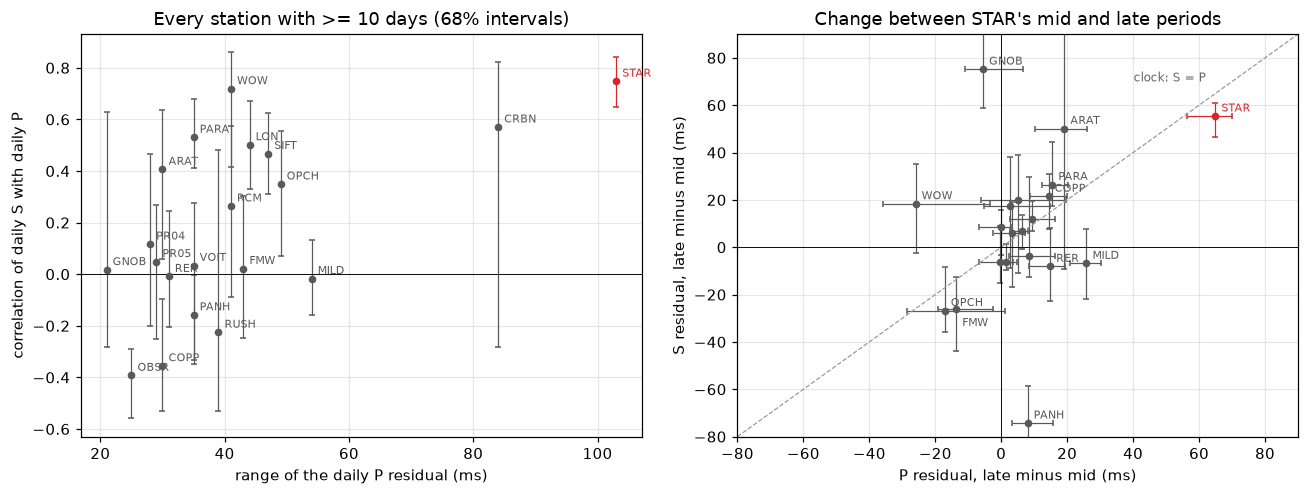

In [18]:
MIN_DAYS = 10
rank = {}
for s in sorted(res.station.unique()):
    x = timing.daily_residuals(res, s)
    if len(x) < MIN_DAYS:
        continue
    rank[s] = p_s_stats(x)
    rank[s]["picks"] = int((res.station == s).sum())
    for ph in "PS":
        est, lo, hi, n_mid, n_late = late_minus_mid(res, s, f"res_{ph.lower()}")
        rank[s].update({f"{ph} change": 1000 * est, f"{ph} lo": 1000 * lo, f"{ph} hi": 1000 * hi})
    rank[s]["picks late"] = n_late
rank = pd.DataFrame(rank).T.sort_values("P range (ms)", ascending=False)

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.6))
for s, x in rank.iterrows():
    c = "tab:red" if s == "STAR" else "0.35"
    ax0.errorbar(x["P range (ms)"], x.r, yerr=[[x.r - x.r_lo], [x.r_hi - x.r]], fmt="o", ms=4, color=c, lw=0.8, capsize=2)
    ax0.annotate(s, (x["P range (ms)"], x.r), xytext=(4, 3), textcoords="offset points", fontsize=7, color=c)
    ax1.errorbar(x["P change"], x["S change"], xerr=[[x["P change"] - x["P lo"]], [x["P hi"] - x["P change"]]],
                 yerr=[[x["S change"] - x["S lo"]], [x["S hi"] - x["S change"]]], fmt="o", ms=4, color=c, lw=0.8, capsize=2)
    if s == "STAR" or abs(x["P change"]) > 12 or abs(x["S change"]) > 25:    # label the stations away from the crowd
        ax1.annotate(s, (x["P change"], x["S change"]), xytext=(4, -11) if s == "FMW" else (4, 3), textcoords="offset points",
                     fontsize=7, color=c)
ax0.axhline(0, color="k", lw=0.6)
ax0.set(xlabel="range of the daily P residual (ms)", ylabel="correlation of daily S with daily P",
        title=f"Every station with >= {MIN_DAYS} days (68% intervals)")
lim = np.array([-80, 90])
ax1.plot(lim, lim, "0.6", ls="--", lw=0.8); ax1.text(62, 70, "clock: S = P", fontsize=8, color="0.4", ha="right")
ax1.axhline(0, color="k", lw=0.6); ax1.axvline(0, color="k", lw=0.6)
ax1.set(xlim=lim, ylim=(-80, 90), xlabel="P residual, late minus mid (ms)", ylabel="S residual, late minus mid (ms)",
        title="Change between STAR's mid and late periods")
plt.tight_layout()
others = rank.drop("STAR")
print(f"{len(rank)} stations; besides STAR, P late minus mid from {others['P change'].min():+.0f} to {others['P change'].max():+.0f} ms, "
      f"S from {others['S change'].min():+.0f} to {others['S change'].max():+.0f} ms")
cols = ["picks", "days", "P range (ms)", "slope", "r", "r_lo", "r_hi", "picks late", "P change", "P lo", "P hi", "S change", "S lo", "S hi"]
rank[cols].astype(float).round(2)

**Only STAR shows both signatures of a clock.**

- **Left: range and correlation.** STAR has the largest P range (103 ms) and the highest correlation (0.75), but two others come close on one count each. CRBN has a P range of 84 ms over only 10 days, with a correlation whose interval runs from -0.28 to 0.82. WOW has a correlation of 0.72 (0.41 to 0.86) and slope 0.79, over 11 days with a P range of 41 ms. SIFT, LON and PARA have correlations of about 0.5, but PARA's slope is 1.78, the earth's signature rather than a clock's.
- **Right: late minus mid.** STAR sits alone near the S = P line, 65 ms out in P and 55 in S. Every other station's P changed by between -26 and +26 ms, and none moved P and S together by the same amount: WOW's P *fell* by 26 ms while its S rose by 18 (from only 6 late picks), CRBN changed by +3 in P and +17 in S, OPCH and FMW fell by about 15 ms in P and 26 in S, and PARA and COPP rose by about 15 ms in P and 21 to 26 in S: S 1.5 to 1.9 times P, the pattern of the earth. The large S changes of GNOB and PANH (+75 and -74 ms) come with almost no change in P: noisy S picking.

The stations to ask PNSN about, besides STAR, are CRBN and WOW: not because they show a clock, but because their short, sparse records cannot rule one out; and any station that shares STAR's digitizer, if PNSN says there is one. The Western Rainier Seismic Zone stations 13 to 15 km west of the summit (PR05, SIFT, RUSH, GNOB) look ordinary.

### Exercise 3: can a 50 Hz RCM-STAR pair resolve 20 ms?

The synthetic of section 7 at 50 Hz, with a 3 s lag (a guess for a 4.9 km surface-wave path) and a clock that wanders by ±30 ms over two days. For each coherent ratio and stack length, the share of estimates within 20 ms of the truth, and the peak-to-RMS ratio of each stack. Averaging n hourly stacks keeps the same windows, so only the stack length changes.

hourly stacks, median |error| (ms) without and with the refinement: {0.3: (6.3, 1.3), 0.2: (6.8, 3.2), 0.15: (10.1, 5.3), 0.1: (10.2, 9.3), 0.07: (27.4, 25.1)}
hourly stacks, share within 20 ms without and with the refinement: {0.3: (1.0, 1.0), 0.2: (1.0, 1.0), 0.15: (0.94, 1.0), 0.1: (0.85, 0.81), 0.07: (0.46, 0.46)}
stacks with peak-to-RMS >= 5: 98% within 20 ms (N = 384); below: 48% (N = 66)
stacks with peak-to-RMS >= 8: 100% within 20 ms (N = 315); below: 69% (N = 135)


median |err| (ms)                    share within 20 ms        \
stack (h)                      1      2     4     8                  1     2   
coherent ratio                                                                 
0.07                       25.09  11.05  6.80  5.57               0.46  0.75   
0.10                        9.26   5.55  4.07  3.43               0.81  0.96   
0.15                        5.31   3.81  2.28  1.75               1.00  1.00   
0.20                        3.21   2.43  0.70  0.43               1.00  1.00   
0.30                        1.29   1.08  0.93  0.54               1.00  1.00   

                          median peak-to-RMS                        
stack (h)          4    8                  1      2      4       8  
coherent ratio                                                      
0.07            0.92  1.0               3.58   4.60   6.36    9.10  
0.10            1.00  1.0               6.45   8.63  12.21   17.45  
0.15            1.00  1.0              13.05  18.13  25.50   36.24  
0.20            1.00  1.0              21.89  30.45  42.97   61.11  
0.30            1.00  1.0              42.25  59.31  84.29  116.84

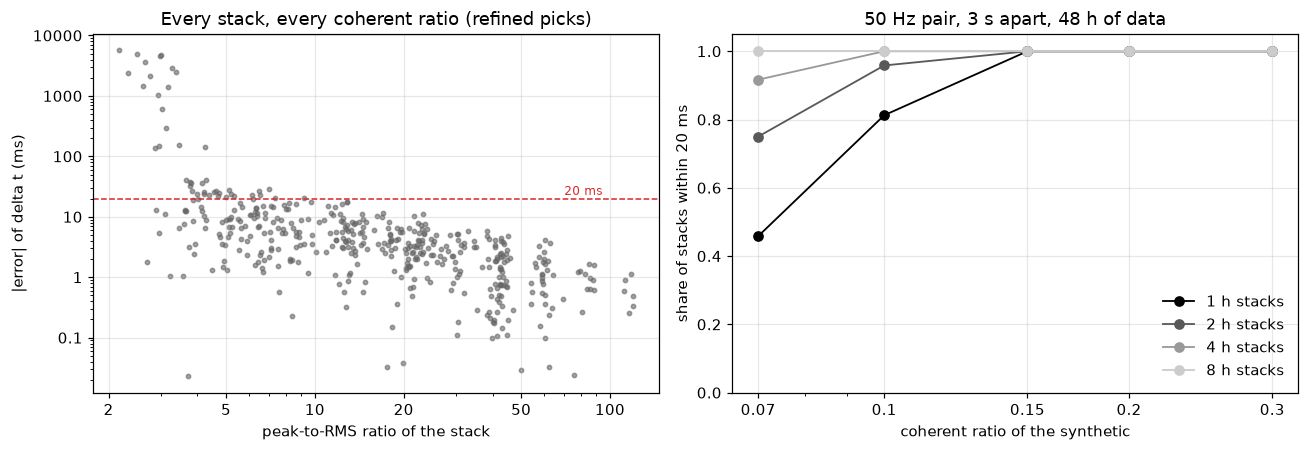

In [19]:
FS_PAIR = 50.0          # Hz: the RCM-STAR pair after decimation (section 8)
LAG_PAIR = 3.0          # s: a guess at the RCM-STAR surface-wave travel time (4.9 km at about 1.6 km/s)
SYNTH_HOURS = 48
STACK_HOURS = [1, 2, 4, 8]

def wander(t_seconds):
    """A clock that wanders by +-30 ms over two days."""
    return 0.03 * np.sin(2 * np.pi * np.asarray(t_seconds, float) / (SYNTH_HOURS * 3600))

rows = []
for ratio in [0.3, 0.2, 0.15, 0.1, 0.07]:
    st3, truth3 = timing.synthetic_pair(hours=SYNTH_HOURS, fs=FS_PAIR, lag_s=LAG_PAIR, delta_t_fn=wander, snr=ratio, seed=1)
    a3, b3, fs3, t03 = timing.align_pair(st3[0], st3[1])
    cc3, mids3, lags3 = timing.ccf_windows(a3, b3, fs3, timing.CCParams())
    cch3, _ = timing.stack_by_hour(cc3, mids3, t03)
    for n in STACK_HOURS:                                       # average n consecutive hourly stacks
        k = len(cch3) // n
        stk = cch3[:k * n].reshape(k, n, -1).mean(axis=1)
        tru = truth3[:k * n].reshape(k, n).mean(axis=1)
        for refine in (False, True):
            est, _ = timing.delta_t_from_lags(timing.peak_lag(stk, lags3, refine=refine, side="pos"), anchor=LAG_PAIR)
            err = np.abs(est - tru)
            rows.append({"coherent ratio": ratio, "stack (h)": n, "refined": refine, "err": err,
                         "ptr": peak_to_rms(stk, lags3, LAG_PAIR)})
sweep = pd.DataFrame(rows)
ref = sweep[sweep.refined].copy()
ref["median |err| (ms)"] = [1000 * np.median(e) for e in ref.err]
ref["share within 20 ms"] = [np.mean(e <= REPORT_THRESHOLD_S) for e in ref.err]
ref["median peak-to-RMS"] = [np.median(p_) for p_ in ref.ptr]
nearest = sweep[~sweep.refined & (sweep["stack (h)"] == 1)]
refined1 = ref[ref["stack (h)"] == 1]
print("hourly stacks, median |error| (ms) without and with the refinement:",
      {r_: (round(1000 * float(np.median(e0)), 1), round(1000 * float(np.median(e1)), 1))
       for r_, e0, e1 in zip(nearest["coherent ratio"], nearest.err, refined1.err)})
print("hourly stacks, share within 20 ms without and with the refinement:",
      {r_: (round(float(np.mean(e0 <= REPORT_THRESHOLD_S)), 2), round(float(np.mean(e1 <= REPORT_THRESHOLD_S)), 2))
       for r_, e0, e1 in zip(nearest["coherent ratio"], nearest.err, refined1.err)})

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4.2))
all_ptr = np.concatenate(ref.ptr.to_list()); all_err = np.concatenate(ref.err.to_list())
ax0.scatter(all_ptr, 1000 * all_err, s=8, color="0.4", alpha=0.6)
ax0.axhline(1000 * REPORT_THRESHOLD_S, color="tab:red", lw=1, ls="--")
ax0.text(70, 1000 * REPORT_THRESHOLD_S * 1.15, "20 ms", color="tab:red", fontsize=8)
ax0.set(xscale="log", yscale="log", xlabel="peak-to-RMS ratio of the stack", ylabel="|error| of delta t (ms)",
        title="Every stack, every coherent ratio (refined picks)")
for n, c in zip(STACK_HOURS, ["k", "0.35", "0.6", "0.8"]):
    g = ref[ref["stack (h)"] == n]
    ax1.plot(g["coherent ratio"], g["share within 20 ms"], "o-", color=c, lw=1.2, label=f"{n} h stacks")
ax1.set(xlabel="coherent ratio of the synthetic", ylabel="share of stacks within 20 ms", ylim=(0, 1.05),
        title=f"{FS_PAIR:.0f} Hz pair, {LAG_PAIR:.0f} s apart, {SYNTH_HOURS} h of data")
ax1.legend(frameon=False, loc="lower right")
ax1.set_xscale("log")
ax0.set_xticks([2, 5, 10, 20, 50, 100]); ax1.set_xticks([0.07, 0.1, 0.15, 0.2, 0.3])
for ax in (ax0, ax1):
    ax.xaxis.set_major_formatter(mticker.FormatStrFormatter("%g")); ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax0.yaxis.set_major_formatter(mticker.FormatStrFormatter("%g"))
plt.tight_layout()
ok = all_err <= REPORT_THRESHOLD_S
for lo_ in (5, 8):
    print(f"stacks with peak-to-RMS >= {lo_}: {np.mean(ok[all_ptr >= lo_]):.0%} within 20 ms (N = {(all_ptr >= lo_).sum()}); "
          f"below: {np.mean(ok[all_ptr < lo_]):.0%} (N = {(all_ptr < lo_).sum()})")
ref.drop(columns=["err", "ptr", "refined"]).set_index(["coherent ratio", "stack (h)"]).round(2).unstack("stack (h)")

**Yes, if the stacks are clear enough, and the peak-to-RMS ratio says when they are.**

- **The refinement is not what decides 20 ms.** At 50 Hz the lag quantum is 20 ms, so a nearest-sample estimate is off by up to 10 ms from rounding, plus the noise. Hourly nearest-sample estimates were within 20 ms about as often as refined ones: all of them at coherent ratios of 0.2 and 0.3, 94 against 100 percent at 0.15, 85 against 81 percent at 0.1. What the refinement buys is resolution below the threshold: at a coherent ratio of 0.3 the median error drops from 6.3 to 1.3 ms, which is what it takes to see the shape of a drift and not just its size.
- **The coherent ratio and the stack length decide.** Every refined hourly estimate is within 20 ms down to a coherent ratio of 0.15 (median errors of 1.3 to 5.3 ms). At 0.1 that drops to 81 percent for hourly stacks, and 2- and 4-hour stacks bring it back to 96 and 100 percent. At 0.07 hourly stacks are right 46 percent of the time, 2-hour stacks 75 and 4-hour stacks 92 percent, and it takes 8-hour stacks to be safe.
- **The criterion to carry to the real data:** every stack with a peak-to-RMS ratio of at least 8 was within 20 ms (N = 315), against 69 percent of those below 8 (N = 135); at a cut of 5 the shares are 98 percent (N = 384) and 48 percent (N = 66). So in the live run, compute the peak-to-RMS ratio of the hourly stacks (the bottom panel of section 8), and where it is below about 8, average neighbouring hours until it is not. Then a 50 Hz RCM-STAR pair resolves 20 ms.

Two cautions. The synthetic is kinder than the mountain: its noise is stationary and comes from one direction, while the real sources change with the weather and the season. And the coherent ratio at which things fail depends on the band and the window length; these numbers are for 10-minute windows whitened at 1 to 6 Hz.

### Exercise 4: does a timing correction have to move the picks too?

The same 25 events from STAR's filtered set for every shift, drawn with a fixed seed. Re-stamping `starttime` moves all three channels together, so phi and dt can only change because the S wave moved relative to the windows placed from the picks. A STAR clock found to be 50 ms late and corrected on the waveforms only is the row -50: the waveforms move 50 ms earlier and the picks stay. The baseline is the unshifted re-measurement, which, like every re-measurement (README, known facts), does not reproduce the filtered set exactly. The first call compiles SWSPy's grid search, so the cell takes a minute or two.

In [20]:
N_EVENTS = 25
SHIFTS = [0.0, -0.05, -0.02, 0.02, 0.05]       # s: the waveforms moved this much later than the picks say
star_cat = data.load_station_catalog("STAR").set_index("evid")
sample = res_o.set_index("evid").loc[np.random.default_rng(0).choice(good.evid.values, N_EVENTS, replace=False)]
events, rows = {}, []
for evid, x in sample.iterrows():
    row = star_cat.loc[evid].copy(); row["evid"] = evid
    events[evid] = (row, data.get_event_stream("STAR", row, allow_download=False))
    for sh in SHIFTS:
        s2 = events[evid][1].copy()
        for tr in s2:
            tr.stats.starttime += sh                   # re-stamp all three channels; the picks stay where they were
        m = measure.measure_event(row, s2, "STAR", s_lat, s_lon, incidence_angle=x.incidence_angle)
        rows.append(dict(m.as_row(), shift_ms=round(1000 * sh)))
shifted = pd.DataFrame(rows)
shifted["passes"] = quality.post_filter_mask(shifted)
base = shifted[shifted.shift_ms == 0].set_index("evid")

def against_base(g):
    """How one set of re-measurements differs from the unshifted baseline, event by event."""
    g = g.set_index("evid"); b0 = base.loc[g.index]
    both = (g.success & b0.success).to_numpy(bool)               # measured both times
    dphi = stats.axial_diff(g.phi.to_numpy(), b0.phi.to_numpy())[both]
    ddt = np.abs(g.dt.to_numpy() - b0.dt.to_numpy())[both]
    return {"measured": int(g.success.sum()), "pass the filter": int(g.passes.sum()), "dt changed": int((ddt > 1e-6).sum()),
            "median |ddt| if changed (ms)": round(1000 * float(np.median(ddt[ddt > 1e-6]))) if (ddt > 1e-6).any() else 0,
            "median |dphi| (deg)": round(float(np.median(dphi)), 1), "|dphi| > 20 deg": int((dphi > 20).sum())}

print(f"{N_EVENTS} events; counts out of {N_EVENTS}, changes among the events measured both times")
pd.DataFrame({sh: against_base(g) for sh, g in shifted.groupby("shift_ms")}).T.rename_axis("waveforms moved (ms)").astype(
    {"measured": int, "pass the filter": int, "dt changed": int, "median |ddt| if changed (ms)": int, "|dphi| > 20 deg": int})

25 events; counts out of 25, changes among the events measured both times


,measured,pass the filter,dt changed,median |ddt| if changed (ms),median |dphi| (deg),|dphi| > 20 deg
waveforms moved (ms),,,,,,
-50,22,13,7,20,4.0,2
-20,23,20,1,20,0.0,2
0,25,24,0,0,0.0,0
20,25,20,5,20,0.0,0
50,25,13,5,60,2.0,1


**Yes. A correction that moves the waveforms and not the picks changes the results about as much as a quality threshold does.**

- Unshifted, 24 of the 25 events pass the post-processing filter again (the 25th tips out, as re-measurements do). With the waveforms moved by 20 ms either way, 20 pass; by 50 ms either way, 13 pass.
- dt changes, by one 0.02 s step, for 1 and 5 events at -20 and +20 ms; at 50 ms for 7 (waveforms earlier) and 5 (later), by a median of 20 and 60 ms. phi is more robust: its median change is 0 to 4 degrees, and at most 2 events turn by more than 20 degrees.
- The direction matters a little. Moving the waveforms earlier, so that the picks sit late on the S wave, stops events from being measured at all (23 and 22 of 25 measured at -20 and -50 ms); moving them later keeps every event measured but changes dt by more.

So when a clock correction is applied to STAR (README, winter item 1), it has to be applied to the picks as well as to the waveforms; otherwise the comparison of "before" and "after" measures the pick misalignment, not the clock. And it makes the same point as notebook 07, section 6, from the other side: the measurement is sensitive to where the S wave sits in the windows at the level of a few hundredths of a second.

### Exercise 5 (stretch): an analyst-free check of the clock

RCM's event windows live in the research repo; the P windows this exercise needs (RCM's vertical, 2 s either side of RCM's P pick) are cut from them into `data/timing/` (the provenance is in the header of `rcm_p_windows.csv`). For each event the cell takes 0.6 s of STAR's vertical P wave around STAR's pick and finds where it matches best in a 1 s window of RCM's around RCM's pick. Neither pick affects the answer except through those windows: if STAR's pick is off, the piece of STAR's waveform shifts and its match at RCM shifts with it. The origin time cancels in a difference. A STAR clock that runs late makes STAR's arrival later and the difference *smaller*, so this residual should look like STAR's P residual upside down.

769 events picked at both stations, 382 with both waveforms in the repo, 232 correlating at >= 0.6 (median correlation 0.65); waveform minus pick difference: median -28 ms, MAD 32 ms
wave-based RCM - STAR difference, late minus mid: -55 ms (68% -73 to -20; 82 and 12 events)
pick-based RCM - STAR difference, late minus mid: -48 ms (68% -66 to -35; 82 and 12 events)
daily wave-based difference against STAR's daily P residual: r = -0.29 (68% -0.51 to -0.06) over 13 days
daily pick-based difference against STAR's daily P residual: r = -0.75 (68% -0.84 to -0.65) over 13 days


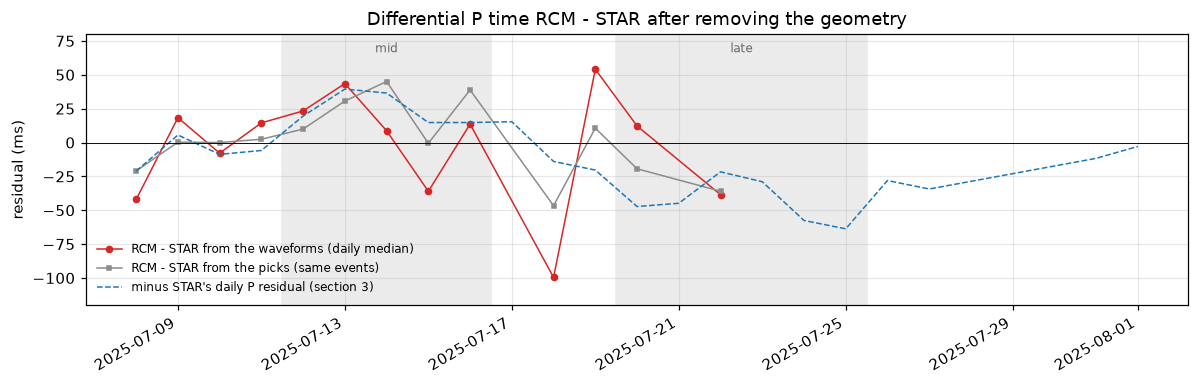

In [21]:
import obspy
RCM_P = paths.DATA / "timing" / "rcm_p_windows"          # cut from the research repo; provenance in the .csv header
index = pd.read_csv(RCM_P.with_suffix(".csv"), comment="#")
rcm_z = obspy.read(str(RCM_P.with_suffix(".mseed")))
star_z = data.load_cached_station("STAR").select(channel=STAR_VERTICAL)
BAND = (2.0, 12.0)                 # Hz: zero-phase bandpass for both stations' P waves
STAR_WIN = (-0.2, 0.4)             # s around STAR's P pick: the piece of STAR's P wave to look for at RCM
RCM_SEARCH = (-0.4, 0.6)           # s around RCM's P pick: where to look for it
CC_MIN = 0.6                       # keep events whose P waves correlate at least this well
MIN_PER_DAY = 3                    # and days with at least this many such events

def near(st_, t, tol):
    hit = [tr for tr in st_ if abs(tr.stats.starttime - t) < tol]
    return hit[0] if hit else None

def bandpassed(tr):
    return tr.copy().detrend("demean").taper(0.05).filter("bandpass", freqmin=BAND[0], freqmax=BAND[1], zerophase=True)

both = res[res.station == "STAR"].merge(res[res.station == "RCM"], on="evid", suffixes=("_s", "_r"))
rows = []
for _, r in both[both.evid.isin(index.evid)].iterrows():
    ps, pr = data.to_utc(r.p_time_s), data.to_utc(r.p_time_r)
    ts_, tr_ = near(star_z, data.to_utc(r.start_time_s), 2.0), near(rcm_z, pr - 2.0, 0.05)
    if ts_ is None or tr_ is None:
        continue
    x = bandpassed(ts_).slice(ps + STAR_WIN[0], ps + STAR_WIN[1]).data
    y_tr = bandpassed(tr_).slice(pr + RCM_SEARCH[0], pr + RCM_SEARCH[1])
    y = y_tr.data
    x = (x - x.mean()) / x.std()
    cc_k = np.array([np.dot(x, (y[k:k + len(x)] - y[k:k + len(x)].mean()) / y[k:k + len(x)].std()) / len(x)
                     for k in range(len(y) - len(x) + 1)])
    k = int(np.argmax(cc_k))
    # the best match starts k samples into RCM's search window; STAR's piece starts STAR_WIN[0] before STAR's pick
    diff_wave = (y_tr.stats.starttime + k / y_tr.stats.sampling_rate - STAR_WIN[0]) - ps
    rows.append({"evid": r.evid, "day": r.origin_time_s.floor("D"), "origin_time": r.origin_time_s, "cc": cc_k[k],
                 "diff_wave": diff_wave, "diff_pick": pr - ps, "diff_geom": (r.R_km_r - r.R_km_s) / vp})
dd = pd.DataFrame(rows)
well = dd[dd.cc >= CC_MIN].copy()
for col in ("diff_wave", "diff_pick"):          # remove the geometry and a constant, as for the residuals
    well[col + "_res"] = well[col] - well.diff_geom - (well[col] - well.diff_geom).median()
w_minus_p = well.diff_wave - well.diff_pick
print(f"{len(both)} events picked at both stations, {len(dd)} with both waveforms in the repo, {len(well)} correlating "
      f"at >= {CC_MIN} (median correlation {dd.cc.median():.2f}); waveform minus pick difference: median "
      f"{1000 * w_minus_p.median():+.0f} ms, MAD {1000 * (w_minus_p - w_minus_p.median()).abs().median():.0f} ms")

for col in ("diff_wave_res", "diff_pick_res"):
    est, lo, hi, n_mid, n_late = late_minus_mid(well.assign(station="STAR"), "STAR", col)
    print(f"{col.split('_')[1]:>4}-based RCM - STAR difference, late minus mid: {1000 * est:+.0f} ms "
          f"(68% {1000 * lo:+.0f} to {1000 * hi:+.0f}; {n_mid} and {n_late} events)")
day = well.groupby("day").agg(wave=("diff_wave_res", "median"), pick=("diff_pick_res", "median"), n=("evid", "size"))
day = day[day.n >= MIN_PER_DAY]
star_p = daily["STAR"].res_p
common = day.index.intersection(star_p.index)
for col in ("wave", "pick"):
    a_, b_ = day.loc[common, col].to_numpy(), star_p.loc[common].to_numpy()
    r0, lo, hi, _ = stats.bootstrap(np.arange(len(a_)), lambda i: np.corrcoef(a_[i], b_[i])[0, 1])
    print(f"daily {col}-based difference against STAR's daily P residual: r = {r0:+.2f} (68% {lo:+.2f} to {hi:+.2f}) over {len(common)} days")

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(day.index, 1000 * day.wave, "o-", ms=4, color="tab:red", lw=1, label="RCM - STAR from the waveforms (daily median)")
ax.plot(day.index, 1000 * day.pick, "s-", ms=3, color="0.55", lw=1, label="RCM - STAR from the picks (same events)")
ax.plot(star_p.index, -1000 * star_p, "--", color="tab:blue", lw=1, label="minus STAR's daily P residual (section 3)")
ax.axhline(0, color="k", lw=0.6); shade_periods(ax, label=True)
ax.set(ylabel="residual (ms)", ylim=(-120, 80), title="Differential P time RCM - STAR after removing the geometry")
ax.legend(loc="lower left", fontsize=8, frameon=False)
fig.autofmt_xdate(); plt.tight_layout()

**The waveforms see the clock change, but day by day they are noisy.**

- Of 382 events with both waveforms, 232 correlate at 0.6 or better (median correlation 0.65). P waves recorded 5 km apart travel different paths and sit on different rock, so they look less alike than the same station's records of two nearby events. The waveform difference is 28 ms smaller than the pick difference (median; MAD 32 ms); a constant offset like that is absorbed by the geometry constant and does not affect the changes.
- **Late minus mid**, the waveform-based RCM-minus-STAR difference fell by 55 ms (68 percent interval -73 to -20 ms), against 48 ms (-66 to -35) for the picks of the same events: the sign and roughly the size of the change in STAR's P residual in section 3, measured without an analyst. It rests on 82 events in the mid period and only 12 in the late one, hence the wide interval.
- **Day by day**, the pick-based difference tracks STAR's P residual upside down (correlation -0.75, interval -0.84 to -0.65, over 13 days with at least 3 good events), but that is partly circular: it contains STAR's own P pick. The waveform-based difference follows the dashed curve from 8 to 13 July and then scatters (about -100 ms on 18 July and +54 ms on 19 July, days with 3 events each), so its correlation is only -0.29 (-0.51 to -0.06).

What this adds: the shared part of the signal cannot be an origin-time error or an analyst's habit. What it does not fix: a few events per day, location error still entering through the distance difference, and RCM's own clock taken on trust. The continuous-noise method of sections 5 to 8 avoids all three, which is why it is diagnostic 2 and this is a stretch exercise.

### Exercise 6 (stretch): could a skew inside STAR's analog chain bias phi?

The same 25 events as exercise 4, with the east channel (after the components are put right, the channel labelled `EHE`) delayed by whole samples against the other two, the first sample repeated to fill the gap. The unskewed row is exercise 4's baseline.

In [22]:
SKEW_SAMPLES = [1, 2, 3]                        # the east channel this many samples late (10, 20, 30 ms at 100 Hz)
rows = []
for evid, x in sample.iterrows():
    row, st0 = events[evid]
    for k in SKEW_SAMPLES:
        s2 = st0.copy()
        e = s2.select(channel="??E")[0]
        e.data = np.r_[np.full(k, e.data[0]), e.data[:-k]]      # delay east against north and vertical
        m = measure.measure_event(row, s2, "STAR", s_lat, s_lon, incidence_angle=x.incidence_angle)
        rows.append(dict(m.as_row(), skew_ms=round(1000 * k / st0[0].stats.sampling_rate)))
skewed = pd.concat([shifted[shifted.shift_ms == 0].assign(skew_ms=0), pd.DataFrame(rows)], ignore_index=True)
skewed["passes"] = quality.post_filter_mask(skewed)
pd.DataFrame({sk: against_base(g) for sk, g in skewed.groupby("skew_ms")}).T.rename_axis("east channel late by (ms)").astype(
    {"measured": int, "pass the filter": int, "dt changed": int, "median |ddt| if changed (ms)": int, "|dphi| > 20 deg": int})

,measured,pass the filter,dt changed,median |ddt| if changed (ms),median |dphi| (deg),|dphi| > 20 deg
east channel late by (ms),,,,,,
0,25,24,0,0,0.0,0
10,24,13,9,20,4.0,1
20,24,11,9,20,8.0,4
30,20,7,6,20,12.0,5


**A skew of one sample already matters.**

- A 10 ms skew (one sample) leaves 13 of the 25 events in the filtered set instead of 24, changes dt by one 0.02 s step for 9 of them and turns phi by a median of 4 degrees.
- At 20 ms, 11 pass, phi turns by a median of 8 degrees and by more than 20 degrees for 4 events. At 30 ms, 7 pass, the median turn is 12 degrees (5 events beyond 20), and 5 events can no longer be measured at all.
- One sample of skew between two channels does more harm than moving all three channels 20 ms against the picks (exercise 4).

Unlike a common clock error, a skew between the channels goes straight into the measurement, because splitting *is* a comparison of the two horizontals. Notebook 03, exercise 5 showed that mismatched geophones skew them by only a few ms; a skew in the telemetry would be a different matter. Whether STAR has one is unknown: its three channels share one sensor model and one response in the metadata (notebook 03, section 1), but each has its own VCO and discriminator, and the noise correlation of section 8 cannot see a skew (it uses one channel). One way to look for it: cross-correlate STAR's two horizontals on P waves arriving from due east or west, where the north channel should see almost nothing coherent and the east channel the whole P wave, and compare with S waves of the same events.

### Exercise 7 (stretch): what does a STAR clock error do to the locations?

A two-stage grid search around PNSN's location (±1.5 km in steps of 100 m, then ±150 m in steps of 10 m), the origin time solved for at every trial point, with the same straight rays, speeds and station terms as everywhere else in this notebook. Each event is located twice, with STAR's picks as they are and 50 ms late, and only the difference is kept, so the crudeness of the model largely cancels.

In [23]:
N_RELOC = 150
MIN_PICKS = 6                                    # stations with P and S at an event, to locate it at all

def locate(g, star_shift=0.0):
    """Grid search for the hypocentre (km) that minimizes the RMS residual, origin time solved for; starts at PNSN's."""
    best = np.array([(g.event_lon.iloc[0] - lon0) * KM_PER_DEG[0], (g.event_lat.iloc[0] - lat0) * KM_PER_DEG[1], g.event_depth.iloc[0]])
    for half_width, step in ((1.5, 0.1), (0.15, 0.01)):
        ax_ = np.arange(-half_width, half_width + 1e-9, step)
        trials = np.column_stack([m.ravel() for m in np.meshgrid(*(best[i] + ax_ for i in range(3)), indexing="ij")])
        r, _ = trial_residuals(g, trials, star_shift)
        best = trials[np.argmin((r ** 2).sum(axis=1))]
    return best

def seen_from_star(p):
    dx, dy, dz = p - sta_xyz.loc["STAR"].to_numpy()
    epi = np.hypot(dx, dy)
    return {"incidence": np.degrees(np.arctan2(epi, dz)), "baz": np.degrees(np.arctan2(dx, dy)) % 360, "R": np.sqrt(epi ** 2 + dz ** 2)}

rows = []
for evid in np.random.default_rng(0).choice(star.evid.unique(), N_RELOC, replace=False):
    g = res[res.evid == evid]
    if len(g) < MIN_PICKS:
        continue
    a_, b_ = locate(g), locate(g, STAR_LATE)
    sa, sb = seen_from_star(a_), seen_from_star(b_)
    rows.append({"evid": evid, "deeper (m)": 1000 * (b_[2] - a_[2]), "sideways (m)": 1000 * np.hypot(*(b_[:2] - a_[:2])),
                 "incidence (deg)": sb["incidence"] - sa["incidence"], "back azimuth (deg)": (sb["baz"] - sa["baz"] + 180) % 360 - 180,
                 "distance to STAR (%)": 100 * (sb["R"] - sa["R"]) / sa["R"], "incidence_before": sa["incidence"]})
moved = pd.DataFrame(rows)
print(f"{len(moved)} of {N_RELOC} sampled events have >= {MIN_PICKS} stations; straight-ray incidence at STAR: median "
      f"{moved.incidence_before.median():.0f} deg")
cols = ["deeper (m)", "sideways (m)", "incidence (deg)", "back azimuth (deg)", "distance to STAR (%)"]
pd.DataFrame({"median": moved[cols].median(), "90th percentile of |change|": moved[cols].abs().quantile(0.9)}).round(1).rename_axis(
    f"STAR {1000 * STAR_LATE:.0f} ms late")

133 of 150 sampled events have >= 6 stations; straight-ray incidence at STAR: median 31 deg


,median,90th percentile of |change|
STAR 50 ms late,,
deeper (m),190.0,260.0
sideways (m),36.1,67.1
incidence (deg),-1.1,2.0
back azimuth (deg),0.5,1.5
distance to STAR (%),4.5,5.9


**A 50 ms STAR clock error moves the locations by less than their own uncertainty, and the splitting inputs hardly at all.**

- Of the 150 sampled events, 133 were picked at enough stations. A late STAR makes them deeper by a median of 190 m (90th percentile 260 m) and moves them sideways by only 36 m: STAR is above the swarm, so the extra time goes into the vertical path.
- STAR's incidence angle changes by a median of -1.1 degrees (90th percentile 2.0) and the back azimuth by 0.5 degrees: far below the 45-degree shear-wave window and the scatter of the fast directions.
- The hypocentral distance to STAR grows by a median of 4.5 percent. Percent anisotropy is dt divided by the S travel time along the ray, so it would fall by about the same fraction of its value: 3.0 percent becomes about 2.9.

So for the splitting results the locations are the least of the problems a STAR clock error causes. For the catalog itself, a couple of hundred metres of depth during a swarm that spans 2 to 6 km is not negligible, and it is systematic: every event with a STAR pick moves the same way.

### Before you use chronfix on STAR: the boundary case as a failing test

`timing.correct_with_model` works around a boundary case in chronfix: segments touching a trigger are dropped, because the trigger interval is closed and times are truncated to seconds. Applied to STAR, that would silently lose the data on both sides of every jump. The smallest model that shows it: six hours with a constant 10 ms clock error and one trigger covering hour 3, and a five-hour trace that crosses the trigger. Correcting it should give two chunks, one on each side of the trigger. The test is written the way it would go into chronos' test suite; here it is run inside `try` so the notebook keeps going.

In [24]:
import obspy
from obspy import UTCDateTime

def test_segments_next_to_a_trigger_are_kept():
    from chronfix.clock_model import ClockModel
    from chronfix.correct import correct_trace
    hours_ = np.arange(np.datetime64("2025-07-10T00"), np.datetime64("2025-07-10T06"), np.timedelta64(1, "h"))
    model_ = ClockModel(hour_times=hours_, delta_t=np.full(len(hours_), 0.01),
                        trigger_starts=np.array(["2025-07-10T03:00:00"], dtype="datetime64[s]"),
                        trigger_ends=np.array(["2025-07-10T03:59:59"], dtype="datetime64[s]"), station="X")
    tr_ = obspy.Trace(np.zeros(5 * 3600 * 10, dtype=np.float32))
    tr_.stats.update({"sampling_rate": 10.0, "starttime": UTCDateTime("2025-07-10T00:00:00")})
    chunks = correct_trace(tr_, model_)
    assert len(chunks) == 2, f"expected 2 corrected chunks (before and after the trigger), got {len(chunks)}"

if timing.CHRONOS_AVAILABLE:
    try:
        test_segments_next_to_a_trigger_are_kept()
        print("test passes: chronfix keeps the segments next to a trigger (the bug has been fixed upstream)")
    except AssertionError as exc:
        print("test fails, as expected for the version installed here:", exc)
    from chronfix.clock_model import ClockModel
    m_ = ClockModel(hour_times=np.arange(np.datetime64("2025-07-10T00"), np.datetime64("2025-07-10T06"), np.timedelta64(1, "h")),
                    delta_t=np.full(6, 0.01), trigger_starts=np.array(["2025-07-10T03:00:00"], dtype="datetime64[s]"),
                    trigger_ends=np.array(["2025-07-10T03:59:59"], dtype="datetime64[s]"), station="X")
    print("stable intervals:", [(str(a), str(b)) for a, b in m_.stable_intervals()])
    for t in ["2025-07-10T02:59:59", "2025-07-10T03:00:00", "2025-07-10T03:59:59", "2025-07-10T04:00:00"]:
        print(f"interp_delta_t({t}) = {m_.interp_delta_t(np.datetime64(t))}")
else:
    print("chronfix is not installed; the test needs it.")

test fails, as expected for the version installed here: expected 2 corrected chunks (before and after the trigger), got 0
stable intervals: [('2025-07-10T00:00:00', '2025-07-10T03:00:00'), ('2025-07-10T03:59:59', '2025-07-10T05:00:00')]
interp_delta_t(2025-07-10T02:59:59) = 0.01
interp_delta_t(2025-07-10T03:00:00) = nan
interp_delta_t(2025-07-10T03:59:59) = nan
interp_delta_t(2025-07-10T04:00:00) = 0.01


The test fails on the installed chronfix: **0 chunks instead of 2**, so the whole five-hour trace is dropped, not just the trigger hour. The printout shows why:

- `stable_intervals` returns segments that end *exactly at* the trigger start (03:00:00) and start *exactly at* the trigger end (03:59:59).
- `interp_delta_t` treats the trigger as a **closed** interval, so delta t is NaN at both of those instants.
- `_resample` needs a finite delta t at the start and the end of each chunk, so it returns nothing for either segment.

Because times are truncated to whole seconds, a segment has to stop a full second short of the trigger to survive, which is exactly the one-second trim `timing.correct_with_model` applies. Use `correct_with_model`, not chronfix directly, until this is fixed upstream.

A real contribution, if you want one: an issue saying *"`correct_trace` silently drops stable segments that touch a trigger"*, the test above, the cause (the endpoints of `stable_intervals` fall inside the closed trigger interval), and two possible fixes: make `stable_intervals` stop one second short of each trigger, or make the trigger check half-open. Open it yourself, from your own GitHub account, after checking that the current chronos version still fails the test; this notebook does not contact GitHub.